1. Setup
2. Data Loading
3. Train/Validation/Test Split
4. Class Distribution Analysis
5. Data Augmentation
6. Class Weights
7. Improved CNN
8. CNN Training
9. CNN Evaluation
10. CNN Confusion Matrix

11. MobileNetV2
12. MobileNetV2 Fine-Tuning
13. MobileNetV2 Evaluation
14. MobileNetV2 Confusion Matrix

15. EfficientNetB0
16. EfficientNetB0 Fine-Tuning
17. EfficientNetB0 Evaluation
18. EfficientNetB0 Confusion Matrix

19. Model Comparison Table
20. Accuracy Plot
21. Precision Plot
22. Recall Plot
23. F1 Plot

24. Dataset Size Experiment
25. Dataset Scaling Plot

26. Save Models
27. Save Results

Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Install TensorFlow
!pip install -q tensorflow

Import Libraries

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import os
import time

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.utils.class_weight import compute_class_weight

Define Directories

In [ ]:
import os
import shutil
import random

random.seed(42)

TRAIN_DIR = "/content/drive/MyDrive/Insect_Data/train"
TEST_DIR  = "/content/drive/MyDrive/Insect_Data/test"

os.makedirs(TEST_DIR, exist_ok=True)

TEST_SPLIT = 0.15

for class_name in os.listdir(TRAIN_DIR):

    source_class_dir = os.path.join(
        TRAIN_DIR,
        class_name
    )

    target_class_dir = os.path.join(
        TEST_DIR,
        class_name
    )

    if not os.path.isdir(source_class_dir):
        continue

    os.makedirs(
        target_class_dir,
        exist_ok=True
    )

    images = os.listdir(
        source_class_dir
    )

    random.shuffle(images)

    n_test = int(
        len(images) * TEST_SPLIT
    )

    test_images = images[:n_test]

    for image in test_images:

        src = os.path.join(
            source_class_dir,
            image
        )

        dst = os.path.join(
            target_class_dir,
            image
        )

        shutil.move(
            src,
            dst
        )

print("Test dataset created.")

Test dataset created.


In [ ]:
Verify

In [ ]:
for class_name in sorted(os.listdir(TEST_DIR)):

    class_path = os.path.join(
        TEST_DIR,
        class_name
    )

    if os.path.isdir(class_path):

        print(
            class_name,
            len(os.listdir(class_path))
        )

Aedes_aegypti 35
Aedes_albopictus 262
Aedes_vexans 787
Amblyomma_americanum 724
Anopheles_stephensi 298
Anopheles_tessellatus 187
Cimex_lectularius 37
Ctenocephalides_canis 487
Ctenocephalides_felis 450
Culex_quinquefasciatus 187
Culex_vishnui 596
Ixodes_ricinus 375
Ixodes_scapularis 32
Pediculus_humanus_capitis 473
Pediculus_humanus_corporis 440
Rhipicephalus_sanguineus 75


Data Loading

In [ ]:
TRAIN_DIR = "/content/drive/MyDrive/Insect_Data/train"

TEST_DIR = "/content/drive/MyDrive/Insect_Data/test"

Training Dataset

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    validation_split=0.20,

    subset="training",

    seed=42,

    image_size=(224,224),

    batch_size=16
)

Found 30901 files belonging to 16 classes.
Using 24721 files for training.


Validation Dataset

In [ ]:
validation_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    validation_split=0.20,

    subset="validation",

    seed=42,

    image_size=(224,224),

    batch_size=16
)

Found 30901 files belonging to 16 classes.
Using 6180 files for validation.


Test Dataset

In [ ]:
test_ds = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    image_size=(224,224),

    batch_size=16,

    shuffle=False
)

Found 5445 files belonging to 16 classes.


In [ ]:
# ==========================================
# COUNT IMAGES IN EACH DATASET
# ==========================================

train_images = 0

for images, labels in train_ds:
    train_images += labels.shape[0]

val_images = 0

for images, labels in validation_ds:
    val_images += labels.shape[0]

test_images = 0

for images, labels in test_ds:
    test_images += labels.shape[0]

print(f"Training Images   : {train_images:,}")
print(f"Validation Images : {val_images:,}")
print(f"Test Images       : {test_images:,}")

Training Images   : 24,721
Validation Images : 6,180
Test Images       : 5,445


In [ ]:
test_labels = []

for _, labels in test_ds:
    test_labels.extend(labels.numpy())

print(sorted(np.unique(test_labels)))
print("Number of classes:", len(np.unique(test_labels)))

[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15)]
Number of classes: 16


Compute Class Weights

In [ ]:
# ==========================================
# COMPUTE CLASS WEIGHTS
# ==========================================

all_labels = np.concatenate(

    [y.numpy() for x, y in train_ds],

    axis=0
)

class_weights = compute_class_weight(

    class_weight='balanced',

    classes=np.unique(all_labels),

    y=all_labels
)

class_weights = dict(
    enumerate(class_weights)
)

print(class_weights)

{0: np.float64(9.841162420382165), 1: np.float64(1.281146351575456), 2: np.float64(0.43134073143495255), 3: np.float64(0.46190209267563526), 4: np.float64(1.1599568318318318), 5: np.float64(1.817720588235294), 6: np.float64(8.93099710982659), 7: np.float64(0.6903764521894549), 8: np.float64(0.7533215504631887), 9: np.float64(1.8349910926365796), 10: np.float64(0.5733070500927644), 11: np.float64(0.9174955463182898), 12: np.float64(10.164884868421053), 13: np.float64(0.732604314841157), 14: np.float64(0.7842956852791878), 15: np.float64(4.612126865671642)}


Data Augmentation

In [ ]:
# ==========================================
# DATA AUGMENTATION
# ==========================================

data_augmentation = keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.15),

    layers.RandomZoom(0.15),

    layers.RandomContrast(0.15)

])

In [ ]:
# ==========================================
# CLASS INFORMATION
# ==========================================

class_names = train_ds.class_names

NUM_CLASSES = len(class_names)

print("Number of Classes:", NUM_CLASSES)

print("\nClasses:")

for i, class_name in enumerate(class_names):
    print(f"{i}: {class_name}")

Number of Classes: 16

Classes:
0: Aedes_aegypti
1: Aedes_albopictus
2: Aedes_vexans
3: Amblyomma_americanum
4: Anopheles_stephensi
5: Anopheles_tessellatus
6: Cimex_lectularius
7: Ctenocephalides_canis
8: Ctenocephalides_felis
9: Culex_quinquefasciatus
10: Culex_vishnui
11: Ixodes_ricinus
12: Ixodes_scapularis
13: Pediculus_humanus_capitis
14: Pediculus_humanus_corporis
15: Rhipicephalus_sanguineus


CNN Model

In [ ]:
# ==========================================
# CNN MODEL
# ==========================================

cnn_model = keras.Sequential([

    layers.Input(
        shape=(224,224,3)
    ),

    data_augmentation,

    layers.Rescaling(
        1./255
    ),

    layers.Conv2D(
        32,
        3,
        padding='same',
        activation='relu'
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(),

    layers.Conv2D(
        64,
        3,
        padding='same',
        activation='relu'
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(),

    layers.Conv2D(
        128,
        3,
        padding='same',
        activation='relu'
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(),

    layers.Conv2D(
        256,
        3,
        padding='same',
        activation='relu'
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        256,
        activation='relu'
    ),

    layers.Dropout(
        0.5
    ),

    layers.Dense(
        NUM_CLASSES,
        activation='softmax'
    )
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         4,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 460,240 (1.76 MB)

 Trainable params: 459,280 (1.75 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
# ==========================================
# PROJECT VARIABLES
# ==========================================

class_names = train_ds.class_names

NUM_CLASSES = len(class_names)

IMG_HEIGHT = 224
IMG_WIDTH = 224

BATCH_SIZE = 16

SEED = 42

print("Classes:", NUM_CLASSES)

Classes: 16


Callbacks

In [ ]:
# ==========================================
# CALLBACKS
# ==========================================

early_stop = keras.callbacks.EarlyStopping(

    monitor='val_loss',

    patience=5,

    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(

    monitor='val_loss',

    factor=0.2,

    patience=2,

    min_lr=1e-6,

    verbose=1
)

In [ ]:
# ==========================================
# COMPILE CNN
# ==========================================

cnn_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.0005
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

In [ ]:
# ==========================================
# TRAIN CNN
# ==========================================

start_time = time.time()

cnn_history = cnn_model.fit(

    train_ds,

    validation_data=validation_ds,

    epochs=20,

    class_weight=class_weights,

    callbacks=[

        early_stop,

        reduce_lr
    ]
)

cnn_training_time = time.time() - start_time

print(
    f"\nTraining Time: {cnn_training_time/60:.2f} minutes"
)

Epoch 1/20
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 45s 24ms/step - accuracy: 0.2131 - loss: 2.3176 - val_accuracy: 0.1026 - val_loss: 3.2761 - learning_rate: 5.0000e-04
Epoch 2/20
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.2991 - loss: 1.9374 - val_accuracy: 0.2133 - val_loss: 2.8266 - learning_rate: 5.0000e-04
Epoch 3/20
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.3689 - loss: 1.7077 - val_accuracy: 0.2155 - val_loss: 2.6810 - learning_rate: 5.0000e-04
Epoch 4/20
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.4161 - loss: 1.5336 - val_accuracy: 0.3303 - val_loss: 3.0227 - learning_rate: 5.0000e-04
Epoch 5/20
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.4679 - loss: 1.3725 - val_accuracy: 0.3833 - val_loss: 2.0387 - learning_rate: 5.0000e-04
Epoch 6/20
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.5009 - loss: 1.2768 - val_accuracy: 0.4992 - val_loss: 1.4461 - learning_rate: 5.0000e-04
Epoch 7/20
1546/1546 ━━━━━━━━━━━━━━━━━━━

In [ ]:
RESULTS_DIR = "/content/drive/MyDrive/Insect_Results"

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

Save CNN

In [ ]:
cnn_model.save(

    os.path.join(
        RESULTS_DIR,
        "cnn_model.keras"
    )
)

Accuracy Curve

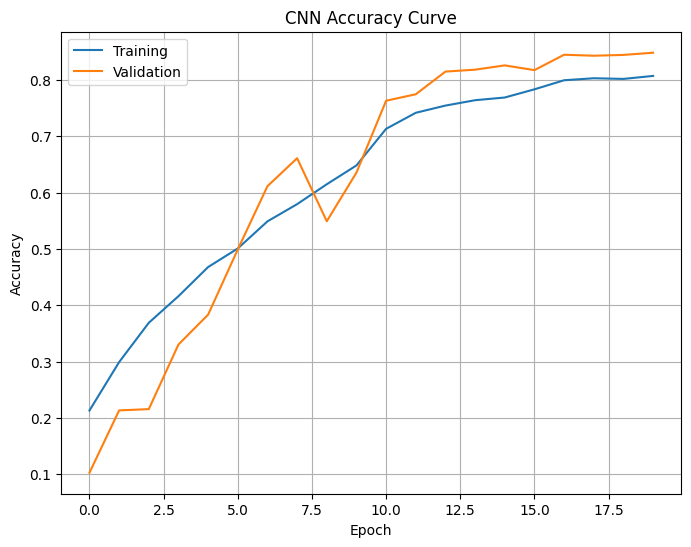

In [ ]:
plt.figure(figsize=(8,6))

plt.plot(
    cnn_history.history['accuracy'],
    label='Training'
)

plt.plot(
    cnn_history.history['val_accuracy'],
    label='Validation'
)

plt.title(
    'CNN Accuracy Curve'
)

plt.xlabel('Epoch')

plt.ylabel('Accuracy')

plt.legend()

plt.grid(True)

plt.show()

Loss Curve

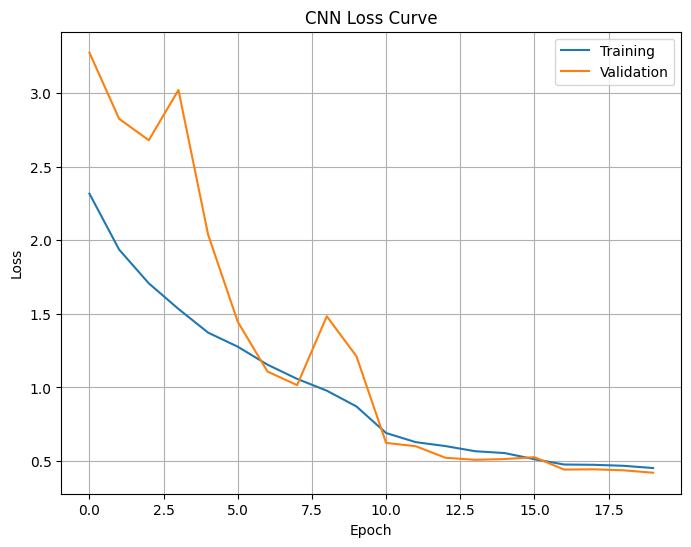

In [ ]:
plt.figure(figsize=(8,6))

plt.plot(
    cnn_history.history['loss'],
    label='Training'
)

plt.plot(
    cnn_history.history['val_loss'],
    label='Validation'
)

plt.title(
    'CNN Loss Curve'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.legend()

plt.grid(True)

plt.show()

Evaluate CNN

In [ ]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    test_ds
)

print(
    f"Test Accuracy: {cnn_test_accuracy:.4f}"
)

341/341 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8542 - loss: 0.4225
Test Accuracy: 0.8542


Predictions

In [ ]:
y_true = []

y_pred = []

for images, labels in test_ds:

    predictions = cnn_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predicted_labels
    )

y_true = np.array(y_true)

y_pred = np.array(y_pred)

Classification Report

In [ ]:
cnn_report = classification_report(

    y_true,

    y_pred,

    labels=list(range(NUM_CLASSES)),

    target_names=class_names,

    output_dict=True,

    zero_division=0
)

cnn_report_df = pd.DataFrame(
    cnn_report
).transpose()

cnn_report_df

,precision,recall,f1-score,support
Aedes_aegypti,0.329897,0.914286,0.484848,35.000000
Aedes_albopictus,0.934066,0.973282,0.953271,262.000000
Aedes_vexans,0.935737,0.758577,0.837895,787.000000
Amblyomma_americanum,0.933227,0.810773,0.867701,724.000000
Anopheles_stephensi,0.977273,0.865772,0.918149,298.000000
Anopheles_tessellatus,0.593857,0.930481,0.725000,187.000000
Cimex_lectularius,1.000000,1.000000,1.000000,37.000000
Ctenocephalides_canis,0.908537,0.917864,0.913177,487.000000
Ctenocephalides_felis,0.957447,0.900000,0.927835,450.000000
Culex_quinquefasciatus,0.550769,0.957219,0.699219,187.000000


Metrics

In [ ]:
cnn_precision = precision_score(

    y_true,

    y_pred,

    average='macro'
)

cnn_recall = recall_score(

    y_true,

    y_pred,

    average='macro'
)

cnn_f1 = f1_score(

    y_true,

    y_pred,

    average='macro'
)

print("\nCNN RESULTS")

print(
    f"Accuracy : {cnn_test_accuracy:.4f}"
)

print(
    f"Precision: {cnn_precision:.4f}"
)

print(
    f"Recall   : {cnn_recall:.4f}"
)

print(
    f"Macro F1 : {cnn_f1:.4f}"
)


CNN RESULTS
Accuracy : 0.8542
Precision: 0.7911
Recall   : 0.8902
Macro F1 : 0.8168


Confusion Matrix

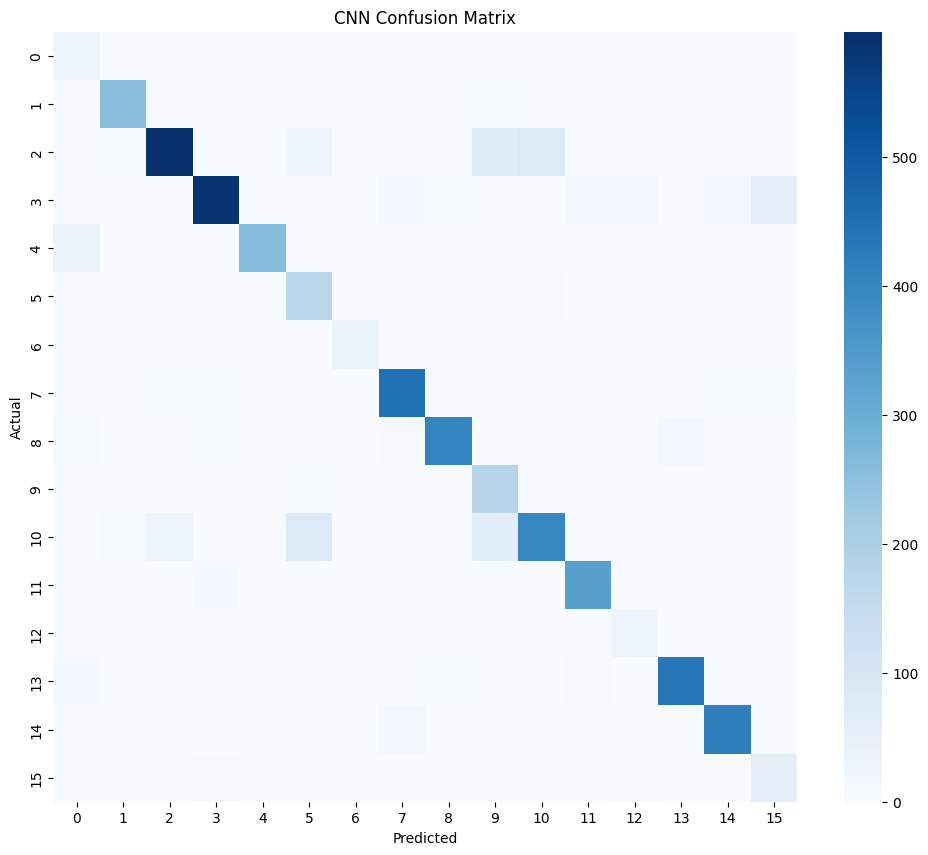

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(
    figsize=(12,10)
)

sns.heatmap(

    cm,

    cmap='Blues'
)

plt.title(
    "CNN Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.show()

Normalized Confusion Matrix

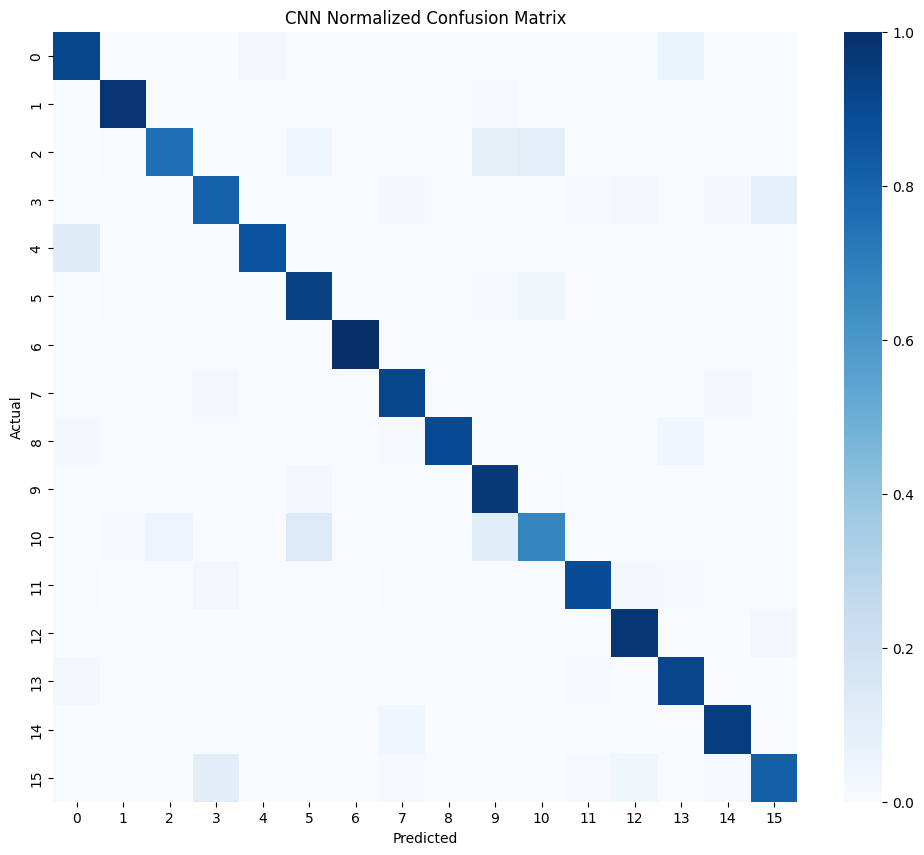

In [ ]:
cm_norm = confusion_matrix(

    y_true,

    y_pred,

    normalize='true'
)

plt.figure(
    figsize=(12,10)
)

sns.heatmap(

    cm_norm,

    cmap='Blues'
)

plt.title(
    "CNN Normalized Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.show()

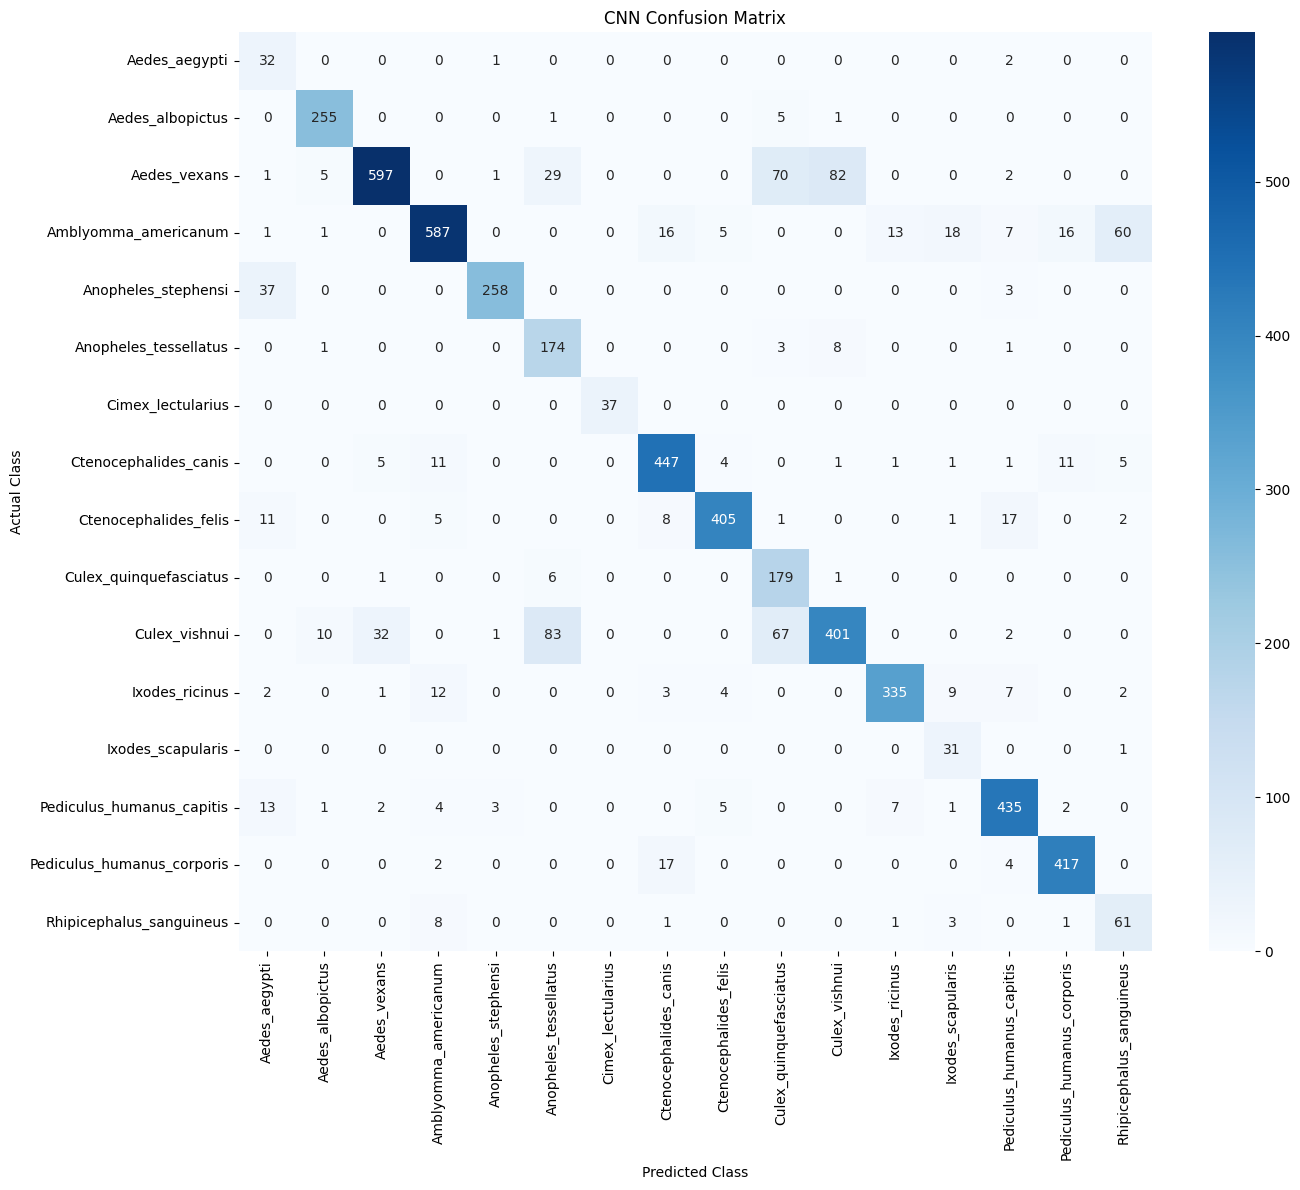

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(14,12))

sns.heatmap(

    cm,

    annot=True,      # Show numbers

    fmt='d',         # Integer format

    cmap='Blues',

    xticklabels=class_names,

    yticklabels=class_names

)

plt.title(
    "CNN Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.xticks(
    rotation=90
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

plt.show()

MobileNetV2 Transfer Learning

In [ ]:
# ==========================================
# MOBILENETV2 BASE MODEL
# ==========================================

base_model = tf.keras.applications.MobileNetV2(

    input_shape=(224,224,3),

    include_top=False,

    weights='imagenet'
)

base_model.trainable = False

print("Base model loaded.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base model loaded.


In [ ]:
# ==========================================
# MOBILENETV2 MODEL
# ==========================================

mobilenet_model = keras.Sequential([

    layers.Input(
        shape=(224,224,3)
    ),

    data_augmentation,

    tf.keras.layers.Lambda(
        tf.keras.applications.mobilenet_v2.preprocess_input
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(
        0.4
    ),

    layers.Dense(
        128,
        activation='relu'
    ),

    layers.Dense(
        NUM_CLASSES,
        activation='softmax'
    )

])

mobilenet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,424,016 (9.25 MB)

 Trainable params: 166,032 (648.56 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Compile

In [ ]:
mobilenet_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

Train Feature Extractor

In [ ]:
start_time = time.time()

mobilenet_history = mobilenet_model.fit(

    train_ds,

    validation_data=validation_ds,

    epochs=10,

    class_weight=class_weights,

    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 41s 24ms/step - accuracy: 0.6686 - loss: 0.9394 - val_accuracy: 0.8076 - val_loss: 0.5194 - learning_rate: 0.0010
Epoch 2/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 35s 23ms/step - accuracy: 0.7874 - loss: 0.5500 - val_accuracy: 0.8777 - val_loss: 0.3483 - learning_rate: 0.0010
Epoch 3/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.8195 - loss: 0.4692 - val_accuracy: 0.8971 - val_loss: 0.3004 - learning_rate: 0.0010
Epoch 4/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 35s 23ms/step - accuracy: 0.8380 - loss: 0.4080 - val_accuracy: 0.9028 - val_loss: 0.2793 - learning_rate: 0.0010
Epoch 5/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.8499 - loss: 0.3725 - val_accuracy: 0.9071 - val_loss: 0.2610 - learning_rate: 0.0010
Epoch 6/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.8604 - loss: 0.3523 - val_accuracy: 0.8892 - val_loss: 0.3071 - learning_rate: 0.0010
Epoch 7/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accura

Fine Tuning

In [ ]:
base_model.trainable = True

In [ ]:
fine_tune_at = 100

for layer in base_model.layers[:fine_tune_at]:

    layer.trainable = False

Recompile

In [ ]:
mobilenet_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

Fine Tune Training

In [ ]:
mobilenet_fine_history = mobilenet_model.fit(

    train_ds,

    validation_data=validation_ds,

    epochs=10,

    class_weight=class_weights,

    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 72s 38ms/step - accuracy: 0.7227 - loss: 0.8774 - val_accuracy: 0.9083 - val_loss: 0.2659 - learning_rate: 1.0000e-05
Epoch 2/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8079 - loss: 0.4919
Epoch 2: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.8182 - loss: 0.4530 - val_accuracy: 0.9217 - val_loss: 0.2320 - learning_rate: 1.0000e-05
Epoch 3/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 54s 35ms/step - accuracy: 0.8470 - loss: 0.3668 - val_accuracy: 0.9230 - val_loss: 0.2217 - learning_rate: 2.0000e-06
Epoch 4/10
1545/1546 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8538 - loss: 0.3499
Epoch 4: ReduceLROnPlateau reducing learning rate to 1e-06.
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 54s 35ms/step - accuracy: 0.8570 - loss: 0.3388 - val_accuracy: 0.9275 - val_loss: 0.2093 - learning_rate: 2.0000e-06
Epoch 5/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 55s 35ms/step - accuracy:

Save Model

In [ ]:
mobilenet_model.save(

    os.path.join(
        RESULTS_DIR,
        "mobilenetv2_model.keras"
    )
)

Test Evaluation

In [ ]:
mobile_test_loss, mobile_test_accuracy = mobilenet_model.evaluate(
    test_ds
)

print(
    f"Test Accuracy: {mobile_test_accuracy:.4f}"
)

341/341 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9003 - loss: 0.2827
Test Accuracy: 0.9003


Predictions

In [ ]:
mobile_y_true = []

mobile_y_pred = []

for images, labels in test_ds:

    predictions = mobilenet_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    mobile_y_true.extend(
        labels.numpy()
    )

    mobile_y_pred.extend(
        predicted_labels
    )

mobile_y_true = np.array(
    mobile_y_true
)

mobile_y_pred = np.array(
    mobile_y_pred
)

Metrics

In [ ]:
mobile_precision = precision_score(

    mobile_y_true,

    mobile_y_pred,

    average='macro'
)

mobile_recall = recall_score(

    mobile_y_true,

    mobile_y_pred,

    average='macro'
)

mobile_f1 = f1_score(

    mobile_y_true,

    mobile_y_pred,

    average='macro'
)

print("\nMobileNetV2 Results")

print(
    f"Accuracy : {mobile_test_accuracy:.4f}"
)

print(
    f"Precision: {mobile_precision:.4f}"
)

print(
    f"Recall   : {mobile_recall:.4f}"
)

print(
    f"Macro F1 : {mobile_f1:.4f}"
)


MobileNetV2 Results
Accuracy : 0.9003
Precision: 0.8437
Recall   : 0.8929
Macro F1 : 0.8603


Confusion Matrix

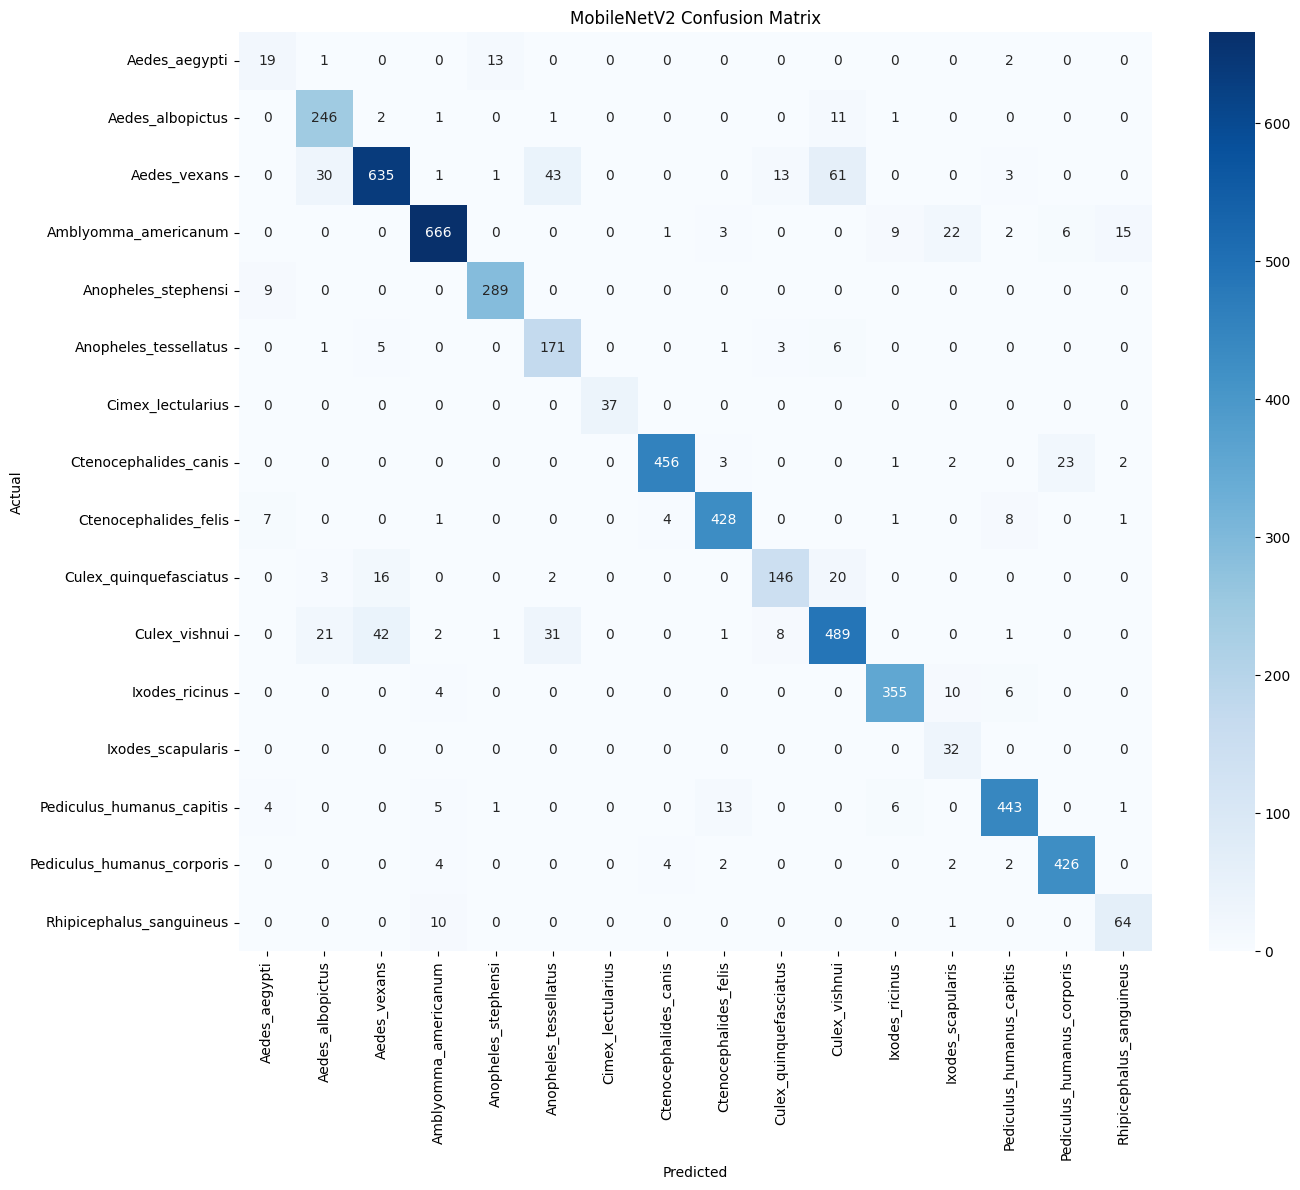

In [ ]:
cm_mobile = confusion_matrix(
    mobile_y_true,
    mobile_y_pred
)

plt.figure(
    figsize=(14,12)
)

sns.heatmap(

    cm_mobile,

    annot=True,

    fmt='d',

    cmap='Blues',

    xticklabels=class_names,

    yticklabels=class_names

)

plt.title(
    "MobileNetV2 Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

# EfficientNetB0 Transfer Learning

### Load EfficientNetB0

In [ ]:
# ==========================================
# EFFICIENTNETB0 BASE MODEL
# ==========================================

efficient_base = tf.keras.applications.EfficientNetB0(

    include_top=False,

    weights='imagenet',

    input_shape=(224,224,3)
)

efficient_base.trainable = False

print("EfficientNetB0 loaded.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded.


Build Model

In [ ]:
# ==========================================
# EFFICIENTNETB0 MODEL
# ==========================================

efficientnet_model = keras.Sequential([

    layers.Input(
        shape=(224,224,3)
    ),

    data_augmentation,

    efficient_base,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(
        0.4
    ),

    layers.Dense(
        128,
        activation='relu'
    ),

    layers.Dense(
        NUM_CLASSES,
        activation='softmax'
    )

])

efficientnet_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,215,603 (16.08 MB)

 Trainable params: 166,032 (648.56 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Compile

In [ ]:
efficientnet_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

Initial Training

In [ ]:
start_time = time.time()

efficient_history = efficientnet_model.fit(

    train_ds,

    validation_data=validation_ds,

    epochs=10,

    class_weight=class_weights,

    callbacks=[
        early_stop,
        reduce_lr
    ]
)

efficient_training_time = time.time() - start_time

print(
    f"Training Time: {efficient_training_time/60:.2f} minutes"
)

Epoch 1/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 49s 25ms/step - accuracy: 0.7657 - loss: 0.6776 - val_accuracy: 0.9303 - val_loss: 0.2212 - learning_rate: 0.0010
Epoch 2/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.8695 - loss: 0.3363 - val_accuracy: 0.9537 - val_loss: 0.1514 - learning_rate: 0.0010
Epoch 3/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.8958 - loss: 0.2794 - val_accuracy: 0.9583 - val_loss: 0.1239 - learning_rate: 0.0010
Epoch 4/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.9100 - loss: 0.2420 - val_accuracy: 0.9652 - val_loss: 0.1041 - learning_rate: 0.0010
Epoch 5/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.9195 - loss: 0.2035 - val_accuracy: 0.9722 - val_loss: 0.0816 - learning_rate: 0.0010
Epoch 6/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accuracy: 0.9288 - loss: 0.1846 - val_accuracy: 0.9741 - val_loss: 0.0789 - learning_rate: 0.0010
Epoch 7/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accura

Fine Tuning

In [ ]:
efficient_base.trainable = True

Freeze Lower Layers

In [ ]:
fine_tune_at = 150

for layer in efficient_base.layers[:fine_tune_at]:

    layer.trainable = False

Recompile

In [ ]:
efficientnet_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

Fine Tune

In [ ]:
efficient_fine_history = efficientnet_model.fit(

    train_ds,

    validation_data=validation_ds,

    epochs=10,

    class_weight=class_weights,

    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 90s 45ms/step - accuracy: 0.7162 - loss: 1.1118 - val_accuracy: 0.8974 - val_loss: 0.3236 - learning_rate: 1.0000e-05
Epoch 2/10
1545/1546 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7950 - loss: 0.5801
Epoch 2: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 67s 43ms/step - accuracy: 0.8099 - loss: 0.5201 - val_accuracy: 0.9307 - val_loss: 0.2052 - learning_rate: 1.0000e-05
Epoch 3/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 67s 43ms/step - accuracy: 0.8436 - loss: 0.4052 - val_accuracy: 0.9341 - val_loss: 0.1890 - learning_rate: 2.0000e-06
Epoch 4/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8497 - loss: 0.3965
Epoch 4: ReduceLROnPlateau reducing learning rate to 1e-06.
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 67s 43ms/step - accuracy: 0.8553 - loss: 0.3720 - val_accuracy: 0.9403 - val_loss: 0.1687 - learning_rate: 2.0000e-06
Epoch 5/10
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 67s 43ms/step - accuracy:

Save Model

In [ ]:
efficientnet_model.save(

    os.path.join(
        RESULTS_DIR,
        "efficientnetb0_model.keras"
    )
)

Test Evaluation

In [ ]:
efficient_test_loss, efficient_test_accuracy = efficientnet_model.evaluate(
    test_ds
)

print(
    f"Test Accuracy: {efficient_test_accuracy:.4f}"
)

341/341 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8961 - loss: 0.3025
Test Accuracy: 0.8961


Predictions

In [ ]:
efficient_y_true = []

efficient_y_pred = []

for images, labels in test_ds:

    predictions = efficientnet_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    efficient_y_true.extend(
        labels.numpy()
    )

    efficient_y_pred.extend(
        predicted_labels
    )

efficient_y_true = np.array(
    efficient_y_true
)

efficient_y_pred = np.array(
    efficient_y_pred
)

Metrics

In [ ]:
efficient_precision = precision_score(

    efficient_y_true,

    efficient_y_pred,

    average='macro'
)

efficient_recall = recall_score(

    efficient_y_true,

    efficient_y_pred,

    average='macro'
)

efficient_f1 = f1_score(

    efficient_y_true,

    efficient_y_pred,

    average='macro'
)

print("\nEfficientNetB0 Results")

print(
    f"Accuracy : {efficient_test_accuracy:.4f}"
)

print(
    f"Precision: {efficient_precision:.4f}"
)

print(
    f"Recall   : {efficient_recall:.4f}"
)

print(
    f"Macro F1 : {efficient_f1:.4f}"
)


EfficientNetB0 Results
Accuracy : 0.8961
Precision: 0.8214
Recall   : 0.9012
Macro F1 : 0.8421


Confusion Matrix

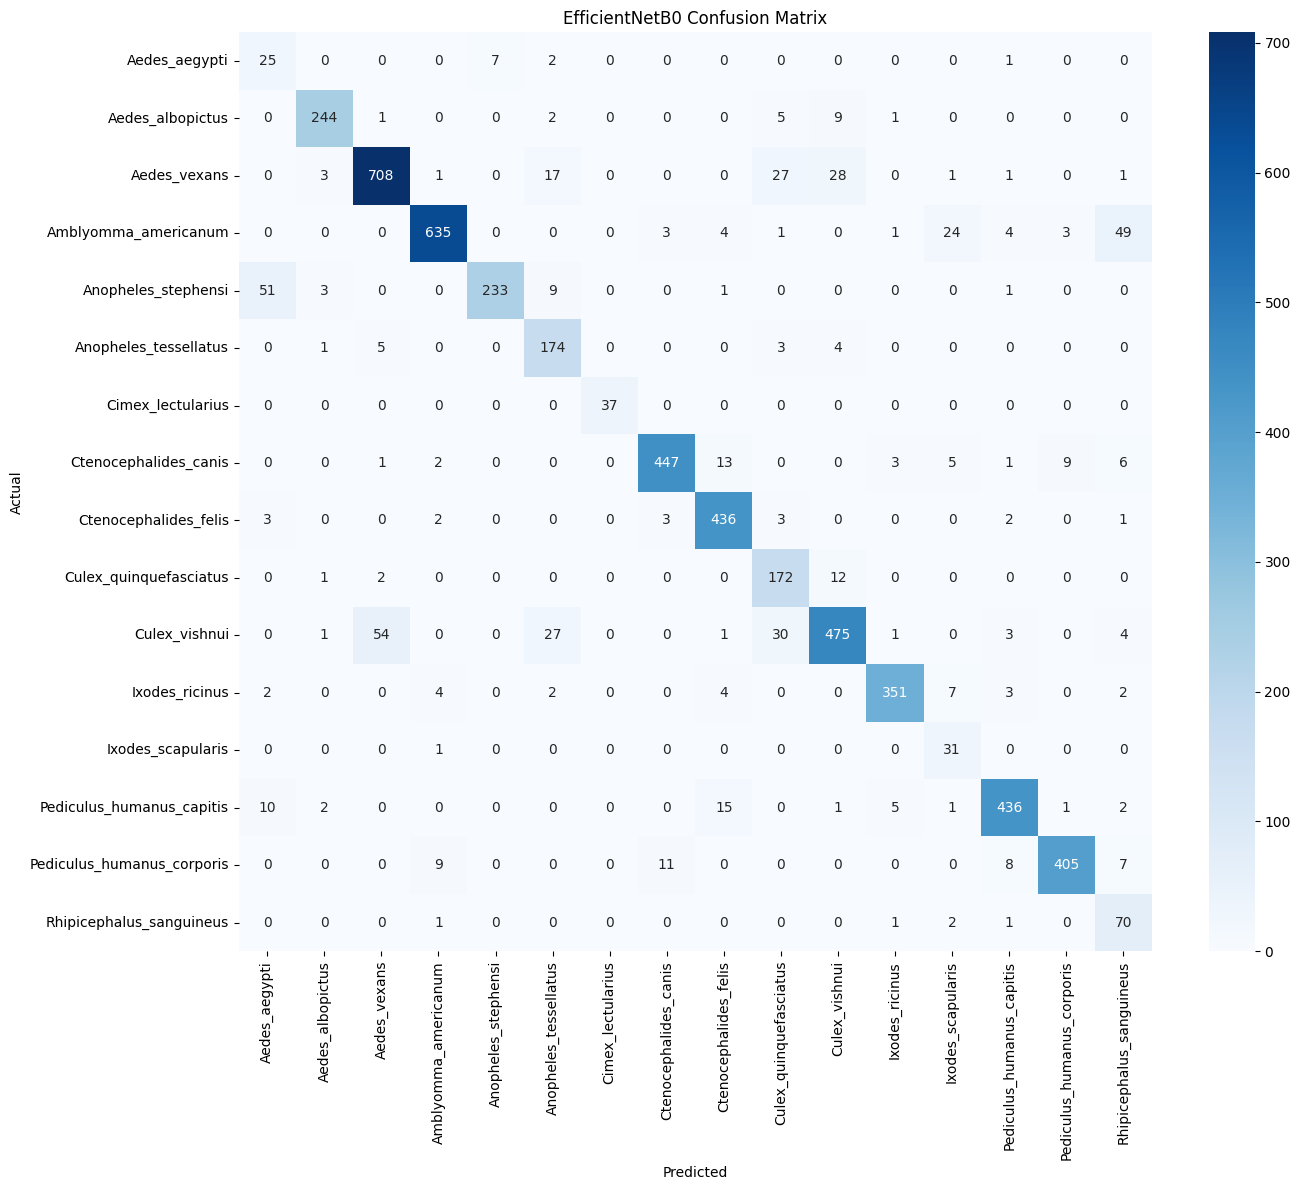

In [ ]:
cm_efficient = confusion_matrix(
    efficient_y_true,
    efficient_y_pred
)

plt.figure(
    figsize=(14,12)
)

sns.heatmap(

    cm_efficient,

    annot=True,

    fmt='d',

    cmap='Blues',

    xticklabels=class_names,

    yticklabels=class_names

)

plt.title(
    "EfficientNetB0 Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

Normalized Confusion Matrix

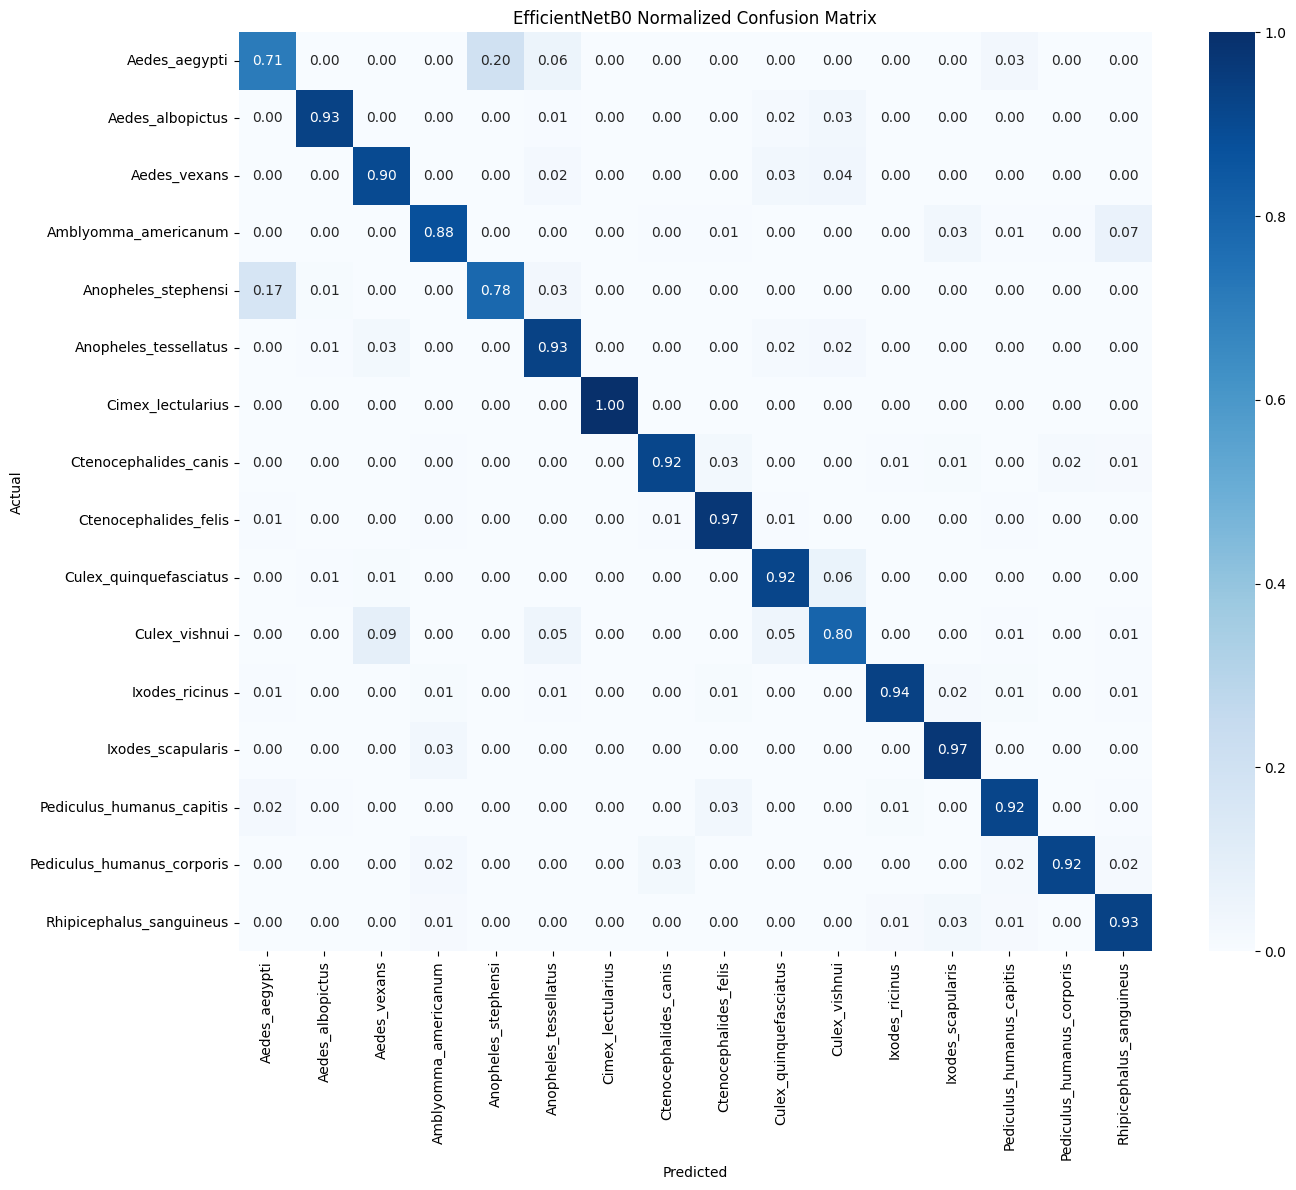

In [ ]:
cm_efficient_norm = confusion_matrix(

    efficient_y_true,

    efficient_y_pred,

    normalize='true'
)

plt.figure(
    figsize=(14,12)
)

sns.heatmap(

    cm_efficient_norm,

    annot=True,

    fmt='.2f',

    cmap='Blues',

    xticklabels=class_names,

    yticklabels=class_names

)

plt.title(
    "EfficientNetB0 Normalized Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

# Model Comparison

Create Results Table

In [ ]:
comparison_df = pd.DataFrame({

    "Model":[

        "CNN",

        "MobileNetV2",

        "EfficientNetB0"
    ],

    "Accuracy":[

        cnn_test_accuracy,

        mobile_test_accuracy,

        efficient_test_accuracy
    ],

    "Precision":[

        cnn_precision,

        mobile_precision,

        efficient_precision
    ],

    "Recall":[

        cnn_recall,

        mobile_recall,

        efficient_recall
    ],

    "Macro_F1":[

        cnn_f1,

        mobile_f1,

        efficient_f1
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,Macro_F1
0,CNN,0.854178,0.791138,0.890242,0.816778
1,MobileNetV2,0.900275,0.843662,0.892888,0.860262
2,EfficientNetB0,0.896051,0.821435,0.901154,0.842078


Save Table

In [ ]:
comparison_df.to_csv(

    os.path.join(
        RESULTS_DIR,
        "model_comparison.csv"
    ),

    index=False
)

Accuracy Comparison Plot

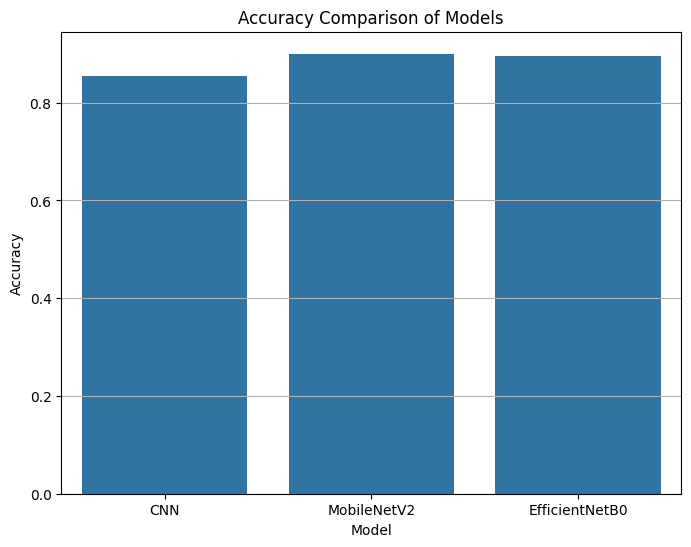

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(

    data=comparison_df,

    x="Model",

    y="Accuracy"
)

plt.title(
    "Accuracy Comparison of Models"
)

plt.ylabel(
    "Accuracy"
)

plt.grid(axis='y')

plt.show()

Precision Comparison Plot

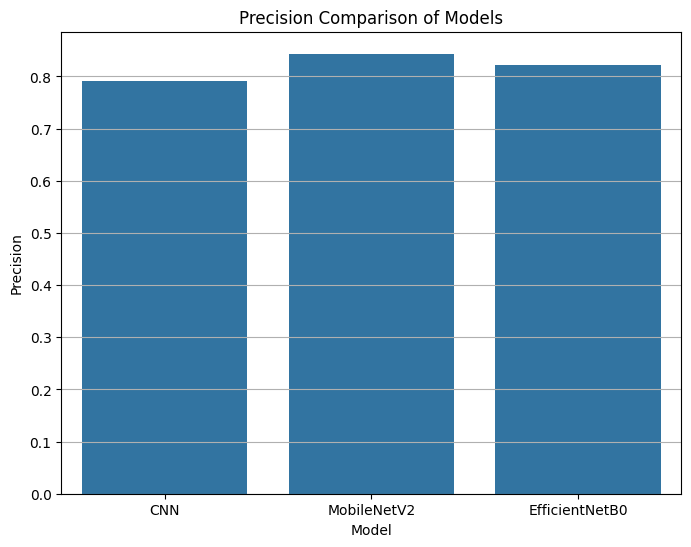

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(

    data=comparison_df,

    x="Model",

    y="Precision"
)

plt.title(
    "Precision Comparison of Models"
)

plt.ylabel(
    "Precision"
)

plt.grid(axis='y')

plt.show()

Recall Comparison Plot

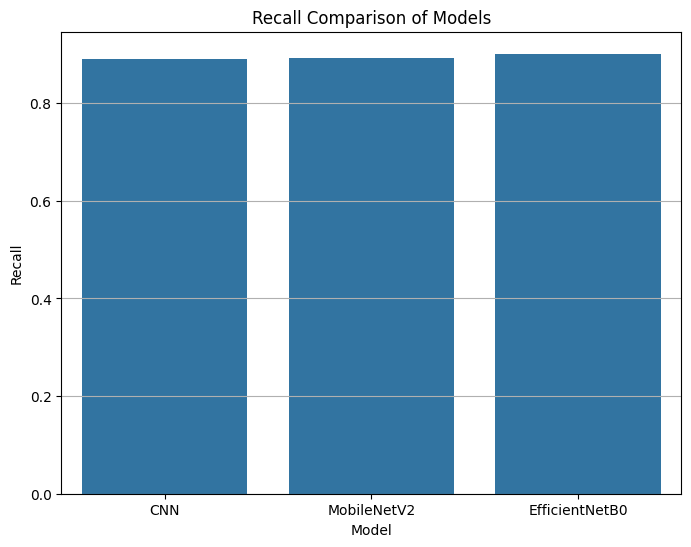

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(

    data=comparison_df,

    x="Model",

    y="Recall"
)

plt.title(
    "Recall Comparison of Models"
)

plt.ylabel(
    "Recall"
)

plt.grid(axis='y')

plt.show()

Macro F1 Comparison Plot

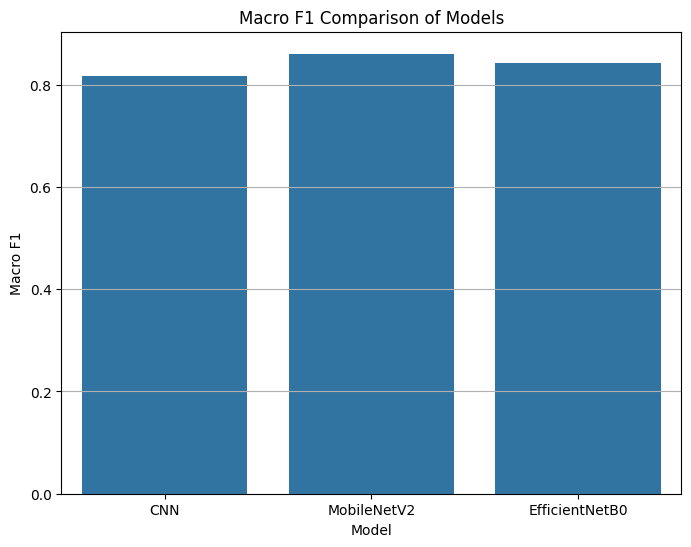

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(

    data=comparison_df,

    x="Model",

    y="Macro_F1"
)

plt.title(
    "Macro F1 Comparison of Models"
)

plt.ylabel(
    "Macro F1"
)

plt.grid(axis='y')

plt.show()

Best Model Selection

In [ ]:
best_model = comparison_df.loc[
    comparison_df["Accuracy"].idxmax()
]

print(best_model)

Model        MobileNetV2
Accuracy        0.900275
Precision       0.843662
Recall          0.892888
Macro_F1        0.860262
Name: 1, dtype: object


Save Final Results

In [ ]:
comparison_df.to_csv(

    os.path.join(
        RESULTS_DIR,
        "final_results.csv"
    ),

    index=False
)

In [ ]:
comparison_df = pd.DataFrame({

    "Model":[
        "CNN",
        "MobileNetV2",
        "EfficientNetB0"
    ],

    "Accuracy":[
        cnn_test_accuracy,
        mobile_test_accuracy,
        efficient_test_accuracy
    ],

    "Precision":[
        cnn_precision,
        mobile_precision,
        efficient_precision
    ],

    "Recall":[
        cnn_recall,
        mobile_recall,
        efficient_recall
    ],

    "Macro_F1":[
        cnn_f1,
        mobile_f1,
        efficient_f1
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,Macro_F1
0,CNN,0.854178,0.791138,0.890242,0.816778
1,MobileNetV2,0.900275,0.843662,0.892888,0.860262
2,EfficientNetB0,0.896051,0.821435,0.901154,0.842078


In [ ]:
comparison_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "model_comparison.csv"
    ),
    index=False
)

Accuracy Comparison

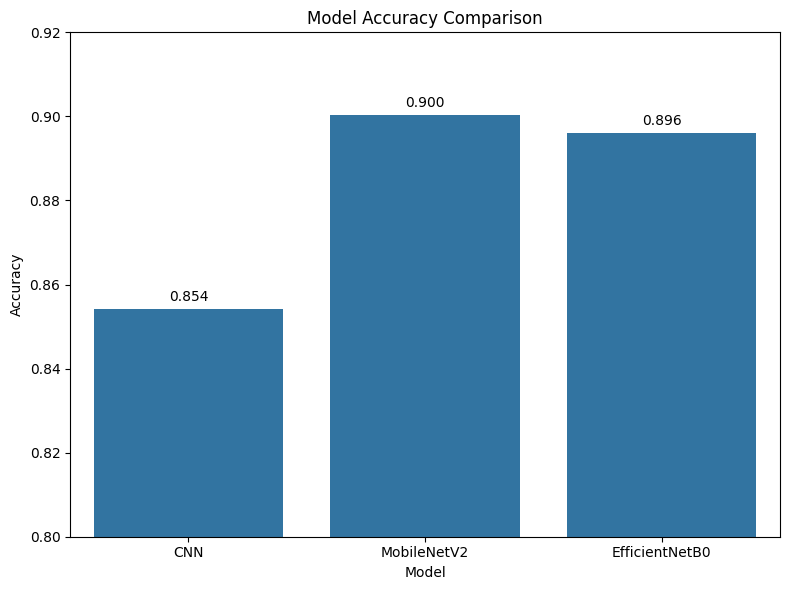

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy"
)

plt.ylim(0.80, 0.92)

plt.title(
    "Model Accuracy Comparison"
)

plt.ylabel(
    "Accuracy"
)

for i, v in enumerate(comparison_df["Accuracy"]):
    plt.text(i, v + 0.002, f"{v:.3f}", ha='center')

plt.tight_layout()

plt.show()

Precision Comparison

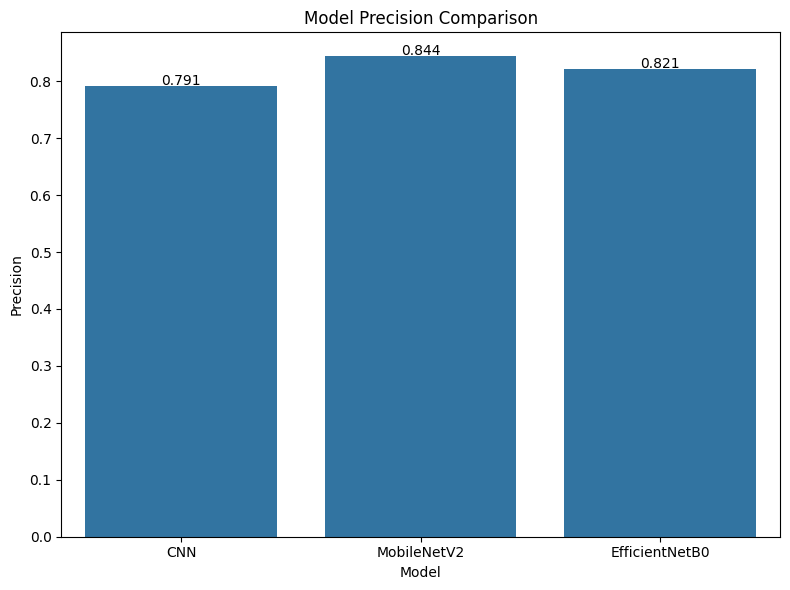

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Precision"
)

plt.title(
    "Model Precision Comparison"
)

for i, v in enumerate(comparison_df["Precision"]):
    plt.text(i, v + 0.002, f"{v:.3f}", ha='center')

plt.tight_layout()

plt.show()

Recall Comparison

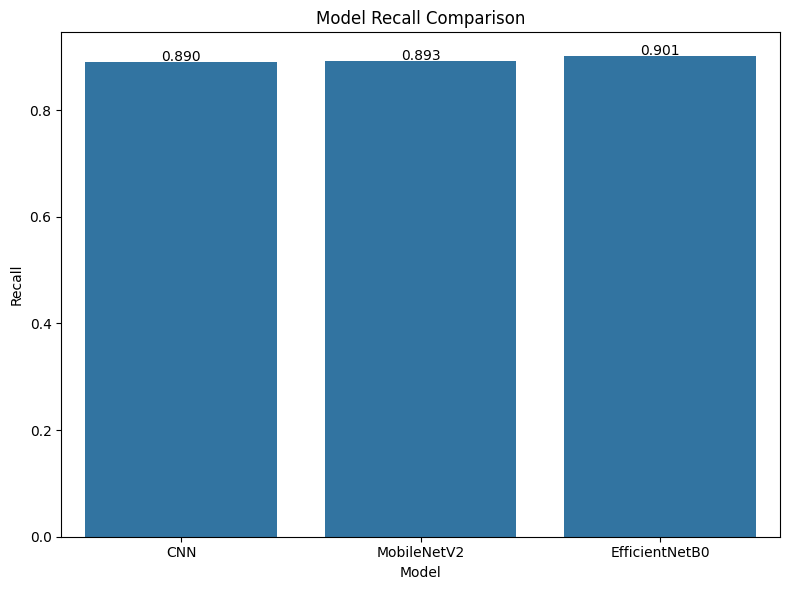

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Recall"
)

plt.title(
    "Model Recall Comparison"
)

for i, v in enumerate(comparison_df["Recall"]):
    plt.text(i, v + 0.002, f"{v:.3f}", ha='center')

plt.tight_layout()

plt.show()

Macro F1 Comparison

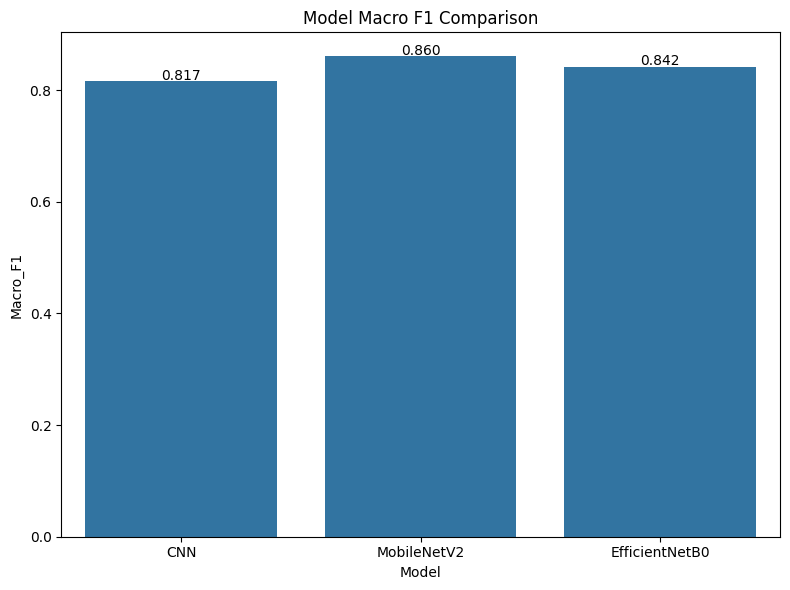

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Macro_F1"
)

plt.title(
    "Model Macro F1 Comparison"
)

for i, v in enumerate(comparison_df["Macro_F1"]):
    plt.text(i, v + 0.002, f"{v:.3f}", ha='center')

plt.tight_layout()

plt.show()

# Dataset Size Experiment

Dataset Size Scaling

In [ ]:
# Create Dataset Subsets
# ==========================================
# DATASET FRACTION FUNCTION
# ==========================================

def create_subset(dataset, fraction):

    total_batches = tf.data.experimental.cardinality(
        dataset
    ).numpy()

    subset_batches = int(
        total_batches * fraction
    )

    subset = dataset.take(
        subset_batches
    )

    return subset

Create 25%, 50%, 100%

In [ ]:
train_25 = create_subset(
    train_ds,
    0.25
)

train_50 = create_subset(
    train_ds,
    0.50
)

train_100 = train_ds

Results Storage

In [ ]:
dataset_scaling_results = []

Lightweight CNN Function

In [ ]:
#We don't want to manually rewrite the CNN.
def build_cnn():

    model = keras.Sequential([

        layers.Input(
            shape=(224,224,3)
        ),

        data_augmentation,

        layers.Rescaling(
            1./255
        ),

        layers.Conv2D(
            32,
            3,
            activation='relu',
            padding='same'
        ),

        layers.BatchNormalization(),

        layers.MaxPooling2D(),

        layers.Conv2D(
            64,
            3,
            activation='relu',
            padding='same'
        ),

        layers.BatchNormalization(),

        layers.MaxPooling2D(),

        layers.Conv2D(
            128,
            3,
            activation='relu',
            padding='same'
        ),

        layers.BatchNormalization(),

        layers.MaxPooling2D(),

        layers.Conv2D(
            256,
            3,
            activation='relu',
            padding='same'
        ),

        layers.BatchNormalization(),

        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            256,
            activation='relu'
        ),

        layers.Dropout(
            0.5
        ),

        layers.Dense(
            NUM_CLASSES,
            activation='softmax'
        )
    ])

    model.compile(

        optimizer=keras.optimizers.Adam(
            0.0005
        ),

        loss='sparse_categorical_crossentropy',

        metrics=['accuracy']
    )

    return model

CNN Scaling Experiment

In [ ]:
fractions = {

    "25%": train_25,

    "50%": train_50,

    "100%": train_100
}

In [ ]:
for name, subset in fractions.items():

    print(
        f"\nTraining CNN on {name}"
    )

    model = build_cnn()

    model.fit(

        subset,

        validation_data=validation_ds,

        epochs=5,

        verbose=1
    )

    loss, acc = model.evaluate(
        test_ds,
        verbose=0
    )

    dataset_scaling_results.append({

        "Model":"CNN",

        "Dataset_Size":name,

        "Accuracy":acc
    })


Training CNN on 25%
Epoch 1/5
386/386 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.2995 - loss: 2.2094 - val_accuracy: 0.0898 - val_loss: 3.5713
Epoch 2/5
386/386 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.3752 - loss: 1.9157 - val_accuracy: 0.4163 - val_loss: 1.7938
Epoch 3/5
386/386 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.4242 - loss: 1.7437 - val_accuracy: 0.3364 - val_loss: 2.0247
Epoch 4/5
386/386 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.4644 - loss: 1.6121 - val_accuracy: 0.3761 - val_loss: 1.9572
Epoch 5/5
386/386 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.5000 - loss: 1.4948 - val_accuracy: 0.3299 - val_loss: 2.3332

Training CNN on 50%
Epoch 1/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 26s 29ms/step - accuracy: 0.3321 - loss: 2.0584 - val_accuracy: 0.3427 - val_loss: 2.0735
Epoch 2/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - accuracy: 0.4423 - loss: 1.6731 - val_accuracy: 0.4215 - val_loss: 1.7042
Epoch 3/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - 

MobileNetV2 Scaling

In [ ]:
def build_mobilenet():

    base = tf.keras.applications.MobileNetV2(

        input_shape=(224,224,3),

        include_top=False,

        weights='imagenet'
    )

    base.trainable = False

    model = keras.Sequential([

        layers.Input(
            shape=(224,224,3)
        ),

        data_augmentation,

        tf.keras.layers.Lambda(
            tf.keras.applications.mobilenet_v2.preprocess_input
        ),

        base,

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation='relu'
        ),

        layers.Dense(
            NUM_CLASSES,
            activation='softmax'
        )
    ])

    model.compile(

        optimizer='adam',

        loss='sparse_categorical_crossentropy',

        metrics=['accuracy']
    )

    return model

In [ ]:
for name, subset in fractions.items():

    print(
        f"\nTraining MobileNetV2 on {name}"
    )

    model = build_mobilenet()

    model.fit(

        subset,

        validation_data=validation_ds,

        epochs=3,

        verbose=1
    )

    loss, acc = model.evaluate(
        test_ds,
        verbose=0
    )

    dataset_scaling_results.append({

        "Model":"MobileNetV2",

        "Dataset_Size":name,

        "Accuracy":acc
    })


Training MobileNetV2 on 25%
Epoch 1/3
386/386 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - accuracy: 0.7348 - loss: 0.8555 - val_accuracy: 0.8225 - val_loss: 0.5447
Epoch 2/3
386/386 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.8617 - loss: 0.4174 - val_accuracy: 0.8537 - val_loss: 0.4370
Epoch 3/3
386/386 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.8914 - loss: 0.3237 - val_accuracy: 0.8850 - val_loss: 0.3426

Training MobileNetV2 on 50%
Epoch 1/3
773/773 ━━━━━━━━━━━━━━━━━━━━ 27s 29ms/step - accuracy: 0.7867 - loss: 0.6543 - val_accuracy: 0.8730 - val_loss: 0.3894
Epoch 2/3
773/773 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.8901 - loss: 0.3220 - val_accuracy: 0.8950 - val_loss: 0.3011
Epoch 3/3
773/773 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.9156 - loss: 0.2445 - val_accuracy: 0.8995 - val_loss: 0.2882

Training MobileNetV2 on 100%
Epoch 1/3
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 41s 23ms/step - accuracy: 0.8418 - loss: 0.4886 - val_accuracy: 0.8764 - val_loss: 0.3633
Epoch 2

EfficientNetB0 Scaling

In [ ]:
def build_efficientnet():

    base = tf.keras.applications.EfficientNetB0(

        include_top=False,

        weights='imagenet',

        input_shape=(224,224,3)
    )

    base.trainable = False

    model = keras.Sequential([

        layers.Input(
            shape=(224,224,3)
        ),

        data_augmentation,

        base,

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation='relu'
        ),

        layers.Dense(
            NUM_CLASSES,
            activation='softmax'
        )
    ])

    model.compile(

        optimizer='adam',

        loss='sparse_categorical_crossentropy',

        metrics=['accuracy']
    )

    return model

In [ ]:
for name, subset in fractions.items():

    print(
        f"\nTraining EfficientNetB0 on {name}"
    )

    model = build_efficientnet()

    model.fit(

        subset,

        validation_data=validation_ds,

        epochs=3,

        verbose=1
    )

    loss, acc = model.evaluate(
        test_ds,
        verbose=0
    )

    dataset_scaling_results.append({

        "Model":"EfficientNetB0",

        "Dataset_Size":name,

        "Accuracy":acc
    })


Training EfficientNetB0 on 25%
Epoch 1/3
386/386 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7892 - loss: 0.6779 - val_accuracy: 0.9060 - val_loss: 0.2964
Epoch 2/3
386/386 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.9166 - loss: 0.2617 - val_accuracy: 0.9354 - val_loss: 0.2060
Epoch 3/3
386/386 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.9422 - loss: 0.1756 - val_accuracy: 0.9506 - val_loss: 0.1558

Training EfficientNetB0 on 50%
Epoch 1/3
773/773 ━━━━━━━━━━━━━━━━━━━━ 33s 31ms/step - accuracy: 0.8449 - loss: 0.4890 - val_accuracy: 0.9214 - val_loss: 0.2287
Epoch 2/3
773/773 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.9407 - loss: 0.1816 - val_accuracy: 0.9576 - val_loss: 0.1228
Epoch 3/3
773/773 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.9563 - loss: 0.1300 - val_accuracy: 0.9644 - val_loss: 0.1020

Training EfficientNetB0 on 100%
Epoch 1/3
1546/1546 ━━━━━━━━━━━━━━━━━━━━ 48s 25ms/step - accuracy: 0.8944 - loss: 0.3363 - val_accuracy: 0.9608 - val_loss: 0.129

Create Scaling Table

In [ ]:
scaling_df = pd.DataFrame(
    dataset_scaling_results
)

scaling_df

,Model,Dataset_Size,Accuracy
0,CNN,25%,0.321028
1,CNN,50%,0.554821
2,CNN,100%,0.714968
3,MobileNetV2,25%,0.877135
4,MobileNetV2,50%,0.896235
5,MobileNetV2,100%,0.937006
6,EfficientNetB0,25%,0.946740
7,EfficientNetB0,50%,0.965289
8,EfficientNetB0,100%,0.977778


Plot Scaling Results

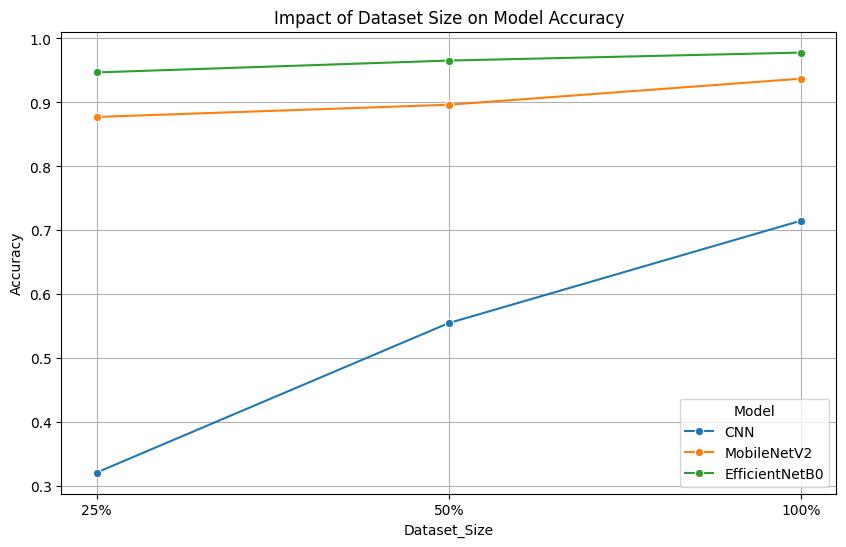

In [ ]:
plt.figure(figsize=(10,6))

sns.lineplot(

    data=scaling_df,

    x="Dataset_Size",

    y="Accuracy",

    hue="Model",

    marker="o"
)

plt.title(
    "Impact of Dataset Size on Model Accuracy"
)

plt.ylabel(
    "Accuracy"
)

plt.grid(True)

plt.show()

Save Everything

In [ ]:
import pickle
import os

RESULTS_DIR = "/content/drive/MyDrive/Insect_Results"
os.makedirs(RESULTS_DIR, exist_ok=True)

artifacts = {
    "comparison_df": comparison_df,
    "cnn_report_df": cnn_report_df,
    "scaling_df": scaling_df if 'scaling_df' in globals() else None,
    "class_names": class_names,
    "cnn_metrics": {
        "accuracy": cnn_test_accuracy,
        "precision": cnn_precision,
        "recall": cnn_recall,
        "f1": cnn_f1
    },
    "mobilenet_metrics": {
        "accuracy": mobile_test_accuracy,
        "precision": mobile_precision,
        "recall": mobile_recall,
        "f1": mobile_f1
    },
    "efficientnet_metrics": {
        "accuracy": efficient_test_accuracy,
        "precision": efficient_precision,
        "recall": efficient_recall,
        "f1": efficient_f1
    }
}

with open(
    os.path.join(
        RESULTS_DIR,
        "thesis_artifacts.pkl"
    ),
    "wb"
) as f:
    pickle.dump(artifacts, f)

print("Artifacts saved successfully.")

Artifacts saved successfully.


Save Training Histories

In [ ]:
import pickle

histories = {
    "cnn_history": cnn_history.history,
    "mobilenet_history": mobilenet_history.history,
    "mobilenet_fine_history": mobilenet_fine_history.history,
    "efficient_history": efficient_history.history,
    "efficient_fine_history": efficient_fine_history.history
}

with open(
    os.path.join(
        RESULTS_DIR,
        "training_histories.pkl"
    ),
    "wb"
) as f:
    pickle.dump(histories, f)

print("Training histories saved.")

Training histories saved.


In [ ]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         4,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,802 (5.26 MB)

 Trainable params: 459,280 (1.75 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 918,562 (3.50 MB)

save history

In [ ]:
import pickle
import os

RESULTS_DIR = "/content/drive/MyDrive/Insect_Results/save"

# Save histories
with open(
    os.path.join(
        RESULTS_DIR,
        "all_training_histories.pkl"
    ),
    "wb"
) as f:

    pickle.dump({

        "cnn_history": cnn_history.history,

        "mobilenet_history": mobilenet_history.history,

        "mobilenet_fine_history": mobilenet_fine_history.history,

        "efficient_history": efficient_history.history,

        "efficient_fine_history": efficient_fine_history.history

    }, f)

print("Histories saved")

Histories saved


Save confusion matrices

In [ ]:
import numpy as np

np.save(
    os.path.join(
        RESULTS_DIR,
        "cnn_confusion_matrix.npy"
    ),
    cm
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "mobilenet_confusion_matrix.npy"
    ),
    cm_mobile
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "efficientnet_confusion_matrix.npy"
    ),
    cm_efficient
)

Save metrics

In [ ]:
comparison_df.to_csv(

    os.path.join(
        RESULTS_DIR,
        "final_model_metrics.csv"
    ),

    index=False
)

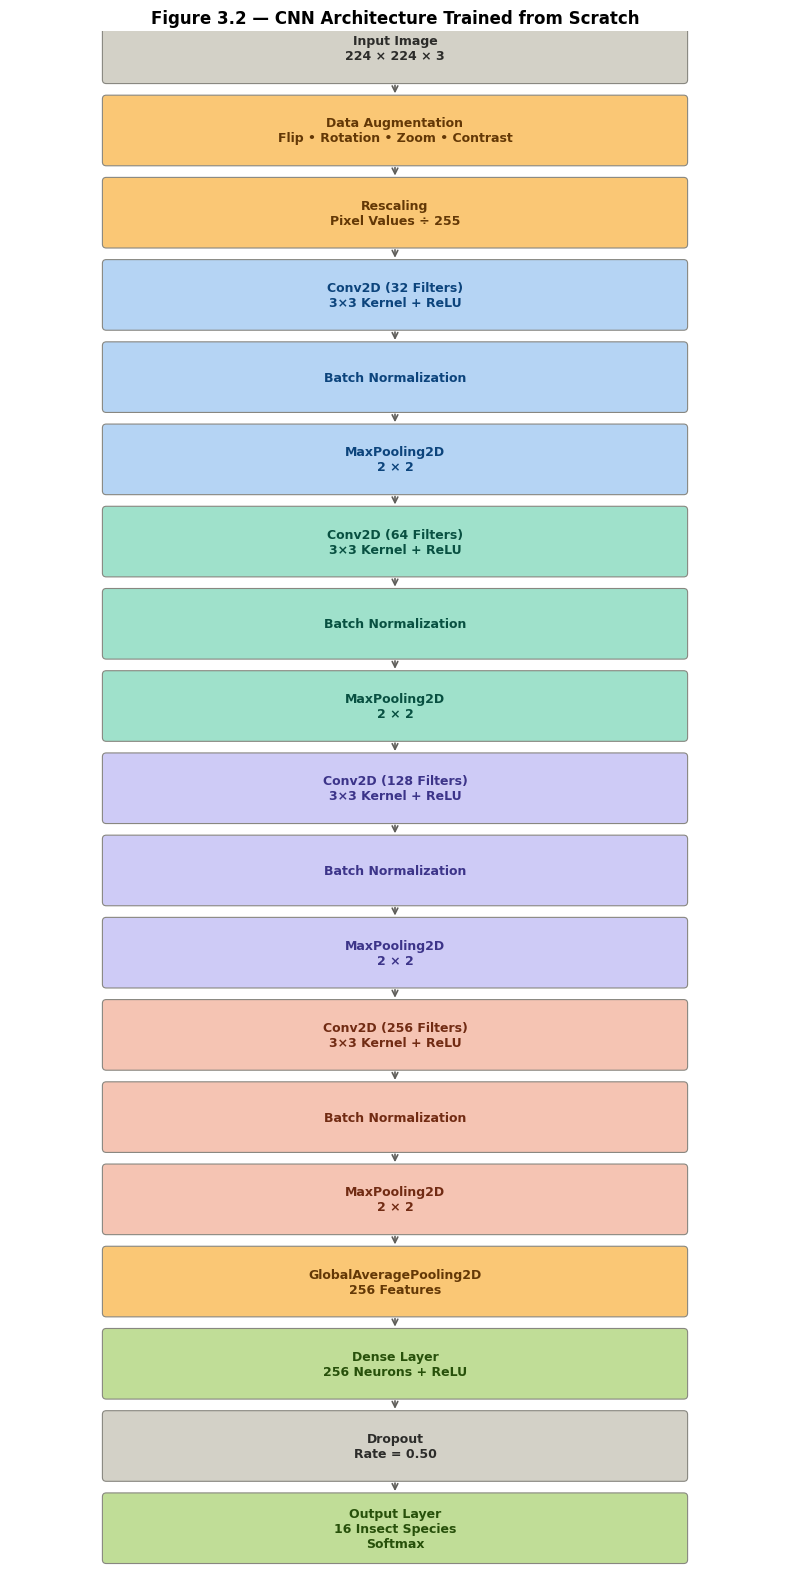

Saved: figure3_2_updated_cnn_architecture.png


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 16))
ax.set_xlim(0, 8)
ax.set_ylim(0, 16)
ax.axis('off')

layers = [

    ("Input Image\n224 × 224 × 3",
     "#D3D1C7", "#2C2C2A"),

    ("Data Augmentation\nFlip • Rotation • Zoom • Contrast",
     "#FAC775", "#633806"),

    ("Rescaling\nPixel Values ÷ 255",
     "#FAC775", "#633806"),

    ("Conv2D (32 Filters)\n3×3 Kernel + ReLU",
     "#B5D4F4", "#0C447C"),

    ("Batch Normalization",
     "#B5D4F4", "#0C447C"),

    ("MaxPooling2D\n2 × 2",
     "#B5D4F4", "#0C447C"),

    ("Conv2D (64 Filters)\n3×3 Kernel + ReLU",
     "#9FE1CB", "#085041"),

    ("Batch Normalization",
     "#9FE1CB", "#085041"),

    ("MaxPooling2D\n2 × 2",
     "#9FE1CB", "#085041"),

    ("Conv2D (128 Filters)\n3×3 Kernel + ReLU",
     "#CECBF6", "#3C3489"),

    ("Batch Normalization",
     "#CECBF6", "#3C3489"),

    ("MaxPooling2D\n2 × 2",
     "#CECBF6", "#3C3489"),

    ("Conv2D (256 Filters)\n3×3 Kernel + ReLU",
     "#F5C4B3", "#712B13"),

    ("Batch Normalization",
     "#F5C4B3", "#712B13"),

    ("MaxPooling2D\n2 × 2",
     "#F5C4B3", "#712B13"),

    ("GlobalAveragePooling2D\n256 Features",
     "#FAC775", "#633806"),

    ("Dense Layer\n256 Neurons + ReLU",
     "#C0DD97", "#27500A"),

    ("Dropout\nRate = 0.50",
     "#D3D1C7", "#2C2C2A"),

    ("Output Layer\n16 Insect Species\nSoftmax",
     "#C0DD97", "#27500A")
]

BOX_H = 0.65
GAP = 0.20
STEP = BOX_H + GAP

for i, (label, fc, tc) in enumerate(layers):

    y = len(layers) * STEP - i * STEP

    box = FancyBboxPatch(
        (1, y - BOX_H),
        6,
        BOX_H,
        boxstyle="round,pad=0.04",
        linewidth=0.8,
        edgecolor="#888780",
        facecolor=fc
    )

    ax.add_patch(box)

    ax.text(
        4,
        y - BOX_H/2,
        label,
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        color=tc
    )

    if i < len(layers)-1:

        ax.annotate(
            "",
            xy=(4, y - BOX_H - GAP + 0.03),
            xytext=(4, y - BOX_H - 0.03),
            arrowprops=dict(
                arrowstyle="->",
                lw=1.2,
                color="#5F5E5A"
            )
        )

ax.set_title(
    "Figure 3.2 — CNN Architecture Trained from Scratch",
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    "figure3_2_updated_cnn_architecture.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Saved: figure3_2_updated_cnn_architecture.png")

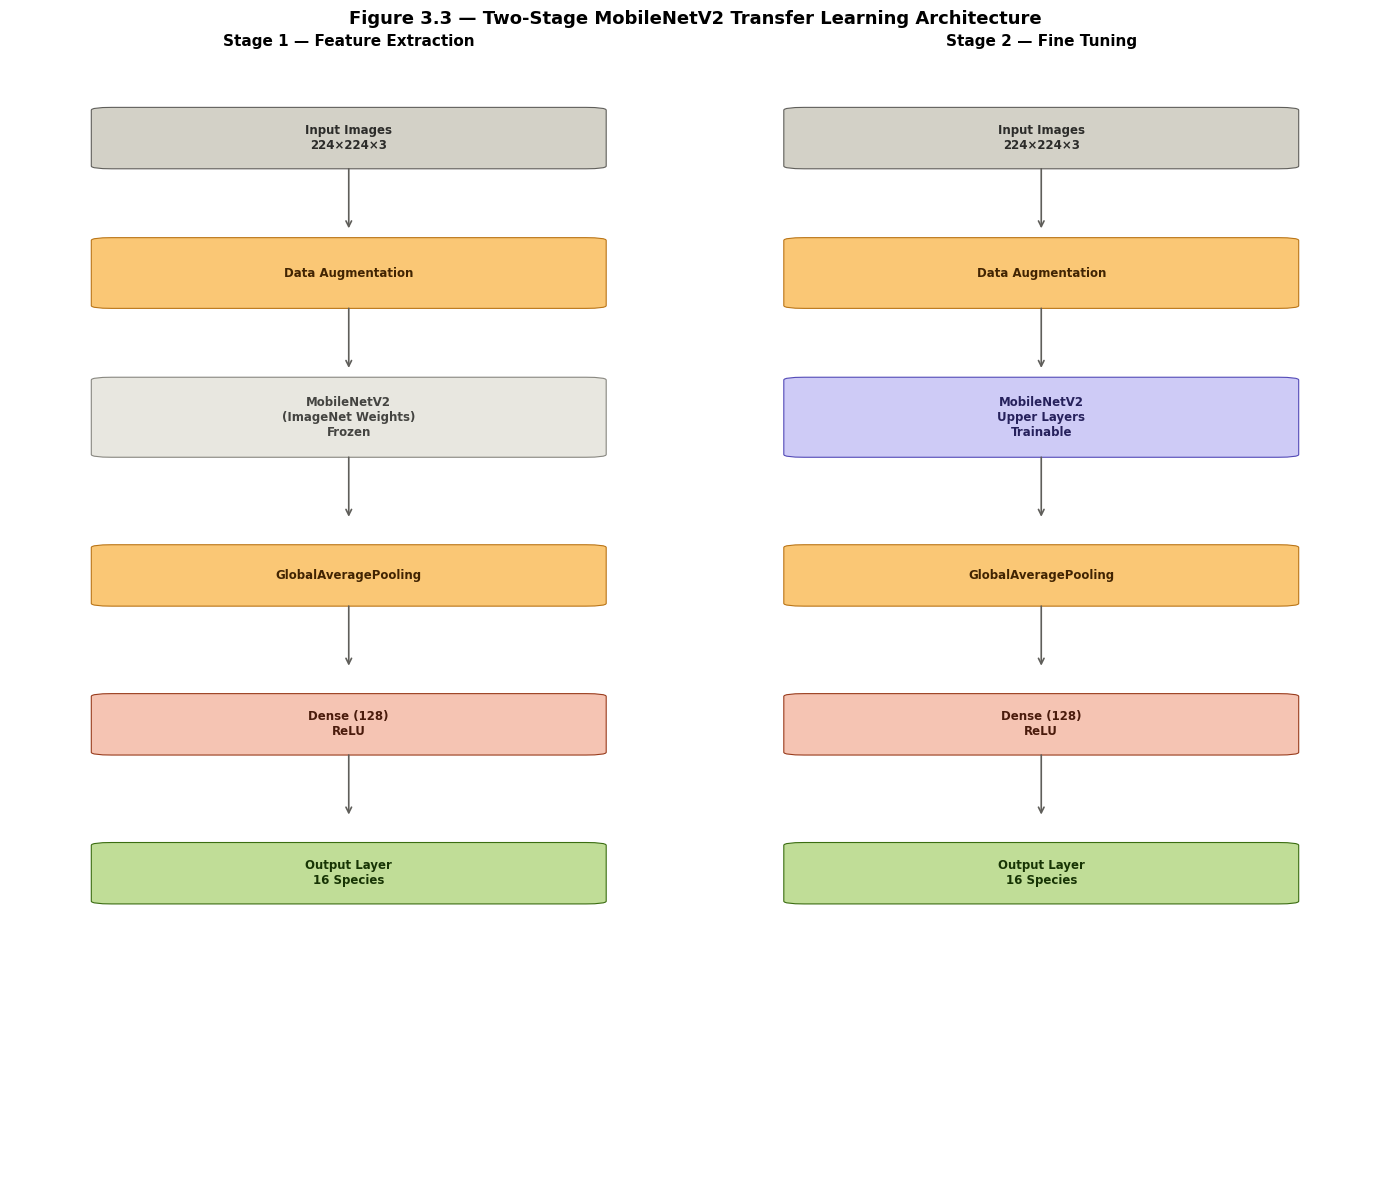

Saved: figure3_3_updated_mobilenetv2_architecture.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(1, 2, figsize=(14, 12))
fig.patch.set_facecolor('white')

# Colors
FROZEN_F = "#E8E7E0"
FROZEN_E = "#888780"
FROZEN_T = "#444441"

UNFROZEN_F = "#CECBF6"
UNFROZEN_E = "#534AB7"
UNFROZEN_T = "#26215C"

POOL_F = "#FAC775"
POOL_E = "#BA7517"
POOL_T = "#412402"

DENSE_F = "#F5C4B3"
DENSE_E = "#993C1D"
DENSE_T = "#4A1B0C"

OUTPUT_F = "#C0DD97"
OUTPUT_E = "#3B6D11"
OUTPUT_T = "#173404"

INPUT_F = "#D3D1C7"
INPUT_E = "#5F5E5A"
INPUT_T = "#2C2C2A"


def draw_box(ax, x, y, w, h, text, fc, ec, tc):

    box = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.03",
        linewidth=0.8,
        edgecolor=ec,
        facecolor=fc
    )

    ax.add_patch(box)

    ax.text(
        x+w/2,
        y+h/2,
        text,
        ha='center',
        va='center',
        fontsize=8.5,
        fontweight='bold',
        color=tc
    )


def arrow(ax, y1, y2):

    ax.annotate(
        "",
        xy=(0.5, y2),
        xytext=(0.5, y1),
        arrowprops=dict(
            arrowstyle="->",
            lw=1.2,
            color="#5F5E5A"
        )
    )


for idx, ax in enumerate(axes):

    ax.set_xlim(0,1)
    ax.set_ylim(0,12)
    ax.axis('off')

    if idx == 0:

        ax.set_title(
            "Stage 1 — Feature Extraction",
            fontsize=11,
            fontweight='bold'
        )

        draw_box(
            ax,0.15,10.8,0.7,0.6,
            "Input Images\n224×224×3",
            INPUT_F,INPUT_E,INPUT_T
        )

        arrow(ax,10.8,10.1)

        draw_box(
            ax,0.15,9.3,0.7,0.7,
            "Data Augmentation",
            POOL_F,POOL_E,POOL_T
        )

        arrow(ax,9.3,8.6)

        draw_box(
            ax,0.15,7.7,0.7,0.8,
            "MobileNetV2\n(ImageNet Weights)\nFrozen",
            FROZEN_F,FROZEN_E,FROZEN_T
        )

        arrow(ax,7.7,7.0)

        draw_box(
            ax,0.15,6.1,0.7,0.6,
            "GlobalAveragePooling",
            POOL_F,POOL_E,POOL_T
        )

        arrow(ax,6.1,5.4)

        draw_box(
            ax,0.15,4.5,0.7,0.6,
            "Dense (128)\nReLU",
            DENSE_F,DENSE_E,DENSE_T
        )

        arrow(ax,4.5,3.8)

        draw_box(
            ax,0.15,2.9,0.7,0.6,
            "Output Layer\n16 Species",
            OUTPUT_F,OUTPUT_E,OUTPUT_T
        )

    else:

        ax.set_title(
            "Stage 2 — Fine Tuning",
            fontsize=11,
            fontweight='bold'
        )

        draw_box(
            ax,0.15,10.8,0.7,0.6,
            "Input Images\n224×224×3",
            INPUT_F,INPUT_E,INPUT_T
        )

        arrow(ax,10.8,10.1)

        draw_box(
            ax,0.15,9.3,0.7,0.7,
            "Data Augmentation",
            POOL_F,POOL_E,POOL_T
        )

        arrow(ax,9.3,8.6)

        draw_box(
            ax,0.15,7.7,0.7,0.8,
            "MobileNetV2\nUpper Layers\nTrainable",
            UNFROZEN_F,UNFROZEN_E,UNFROZEN_T
        )

        arrow(ax,7.7,7.0)

        draw_box(
            ax,0.15,6.1,0.7,0.6,
            "GlobalAveragePooling",
            POOL_F,POOL_E,POOL_T
        )

        arrow(ax,6.1,5.4)

        draw_box(
            ax,0.15,4.5,0.7,0.6,
            "Dense (128)\nReLU",
            DENSE_F,DENSE_E,DENSE_T
        )

        arrow(ax,4.5,3.8)

        draw_box(
            ax,0.15,2.9,0.7,0.6,
            "Output Layer\n16 Species",
            OUTPUT_F,OUTPUT_E,OUTPUT_T
        )

fig.suptitle(
    "Figure 3.3 — Two-Stage MobileNetV2 Transfer Learning Architecture",
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    "figure3_3_updated_mobilenetv2_architecture.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Saved: figure3_3_updated_mobilenetv2_architecture.png")

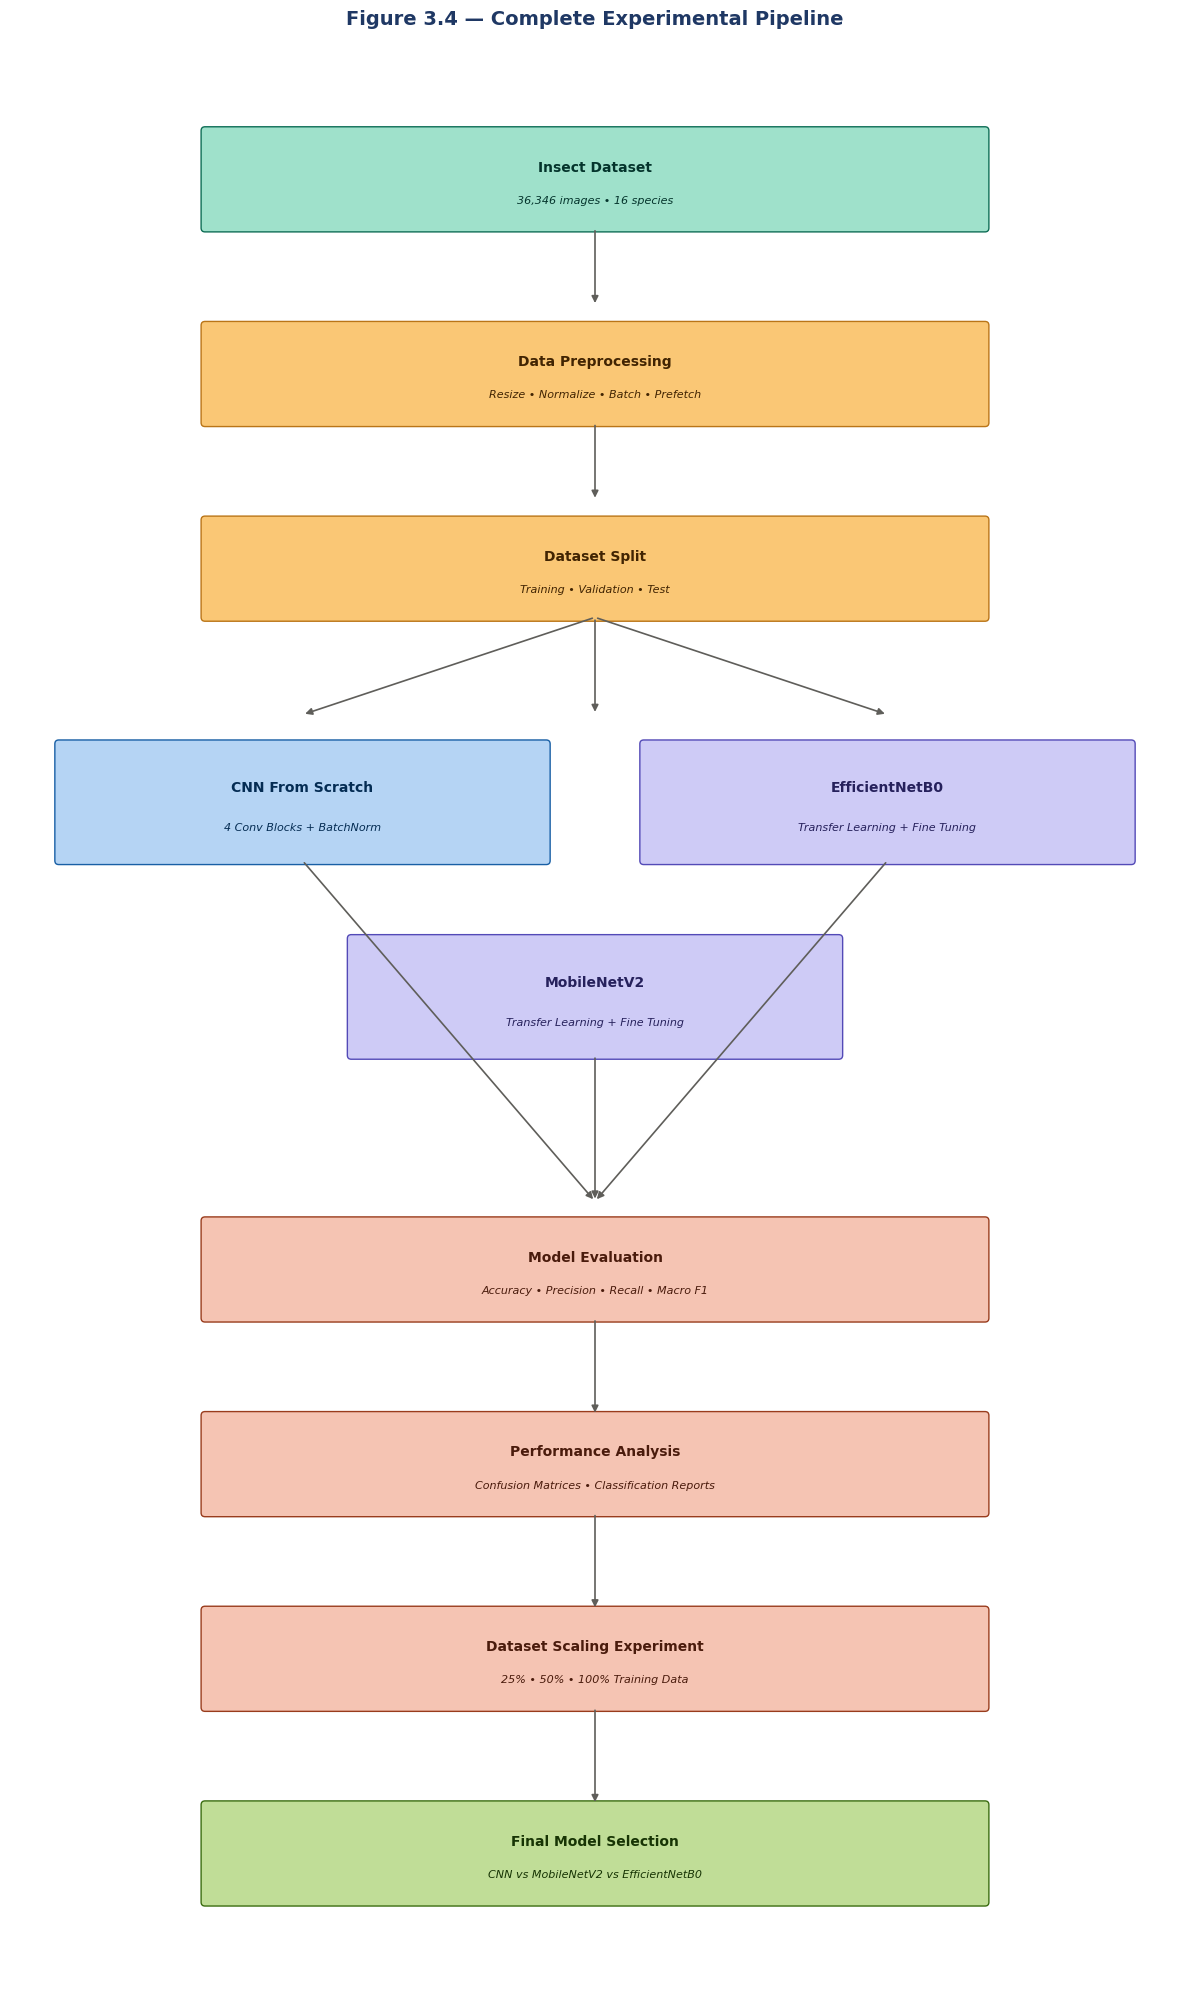

Saved: figure3_4_complete_pipeline.png


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 20))

ax.set_xlim(0, 12)
ax.set_ylim(0, 20)

ax.axis('off')

# -------------------------------------------------
# COLOR PALETTE
# -------------------------------------------------

colors = {

    "dataset": ("#9FE1CB", "#0F6E56", "#04342C"),

    "prep": ("#FAC775", "#BA7517", "#412402"),

    "cnn": ("#B5D4F4", "#185FA5", "#042C53"),

    "transfer": ("#CECBF6", "#534AB7", "#26215C"),

    "results": ("#F5C4B3", "#993C1D", "#4A1B0C"),

    "output": ("#C0DD97", "#3B6D11", "#173404")
}

# -------------------------------------------------
# DRAW BOX FUNCTION
# -------------------------------------------------

def draw_box(x, y, w, h, title, subtitle, color_key):

    fc, ec, tc = colors[color_key]

    box = FancyBboxPatch(

        (x, y),

        w,

        h,

        boxstyle="round,pad=0.04",

        linewidth=1,

        edgecolor=ec,

        facecolor=fc

    )

    ax.add_patch(box)

    ax.text(

        x + w/2,

        y + h*0.62,

        title,

        ha='center',

        va='center',

        fontsize=10,

        fontweight='bold',

        color=tc

    )

    ax.text(

        x + w/2,

        y + h*0.28,

        subtitle,

        ha='center',

        va='center',

        fontsize=8,

        style='italic',

        color=tc

    )

# -------------------------------------------------
# ARROW FUNCTION
# -------------------------------------------------

def draw_arrow(x1, y1, x2, y2):

    ax.annotate(

        "",

        xy=(x2, y2),

        xytext=(x1, y1),

        arrowprops=dict(

            arrowstyle="-|>",

            lw=1.2,

            color="#5F5E5A"

        )

    )

# -------------------------------------------------
# TOP PIPELINE
# -------------------------------------------------

draw_box(

    2, 18,

    8, 1,

    "Insect Dataset",

    "36,346 images • 16 species",

    "dataset"
)

draw_arrow(6,18,6,17.2)

draw_box(

    2,16,

    8,1,

    "Data Preprocessing",

    "Resize • Normalize • Batch • Prefetch",

    "prep"
)

draw_arrow(6,16,6,15.2)

draw_box(

    2,14,

    8,1,

    "Dataset Split",

    "Training • Validation • Test",

    "prep"
)

# -------------------------------------------------
# BRANCHES
# -------------------------------------------------

draw_arrow(6,14,3,13)

draw_arrow(6,14,6,13)

draw_arrow(6,14,9,13)

draw_box(

    0.5,11.5,

    5,1.2,

    "CNN From Scratch",

    "4 Conv Blocks + BatchNorm",

    "cnn"
)

draw_box(

    3.5,9.5,

    5,1.2,

    "MobileNetV2",

    "Transfer Learning + Fine Tuning",

    "transfer"
)

draw_box(

    6.5,11.5,

    5,1.2,

    "EfficientNetB0",

    "Transfer Learning + Fine Tuning",

    "transfer"
)

# -------------------------------------------------
# MERGE
# -------------------------------------------------

draw_arrow(3,11.5,6,8)

draw_arrow(9,11.5,6,8)

draw_arrow(6,9.5,6,8)

draw_box(

    2,6.8,

    8,1,

    "Model Evaluation",

    "Accuracy • Precision • Recall • Macro F1",

    "results"
)

draw_arrow(6,6.8,6,5.8)

draw_box(

    2,4.8,

    8,1,

    "Performance Analysis",

    "Confusion Matrices • Classification Reports",

    "results"
)

draw_arrow(6,4.8,6,3.8)

draw_box(

    2,2.8,

    8,1,

    "Dataset Scaling Experiment",

    "25% • 50% • 100% Training Data",

    "results"
)

draw_arrow(6,2.8,6,1.8)

draw_box(

    2,0.8,

    8,1,

    "Final Model Selection",

    "CNN vs MobileNetV2 vs EfficientNetB0",

    "output"
)

ax.set_title(

    "Figure 3.4 — Complete Experimental Pipeline",

    fontsize=14,

    fontweight='bold',

    color="#1F3864"

)

plt.tight_layout()

plt.savefig(

    "figure3_4_complete_pipeline.png",

    dpi=300,

    bbox_inches='tight',

    facecolor='white'

)

plt.show()

print("Saved: figure3_4_complete_pipeline.png")

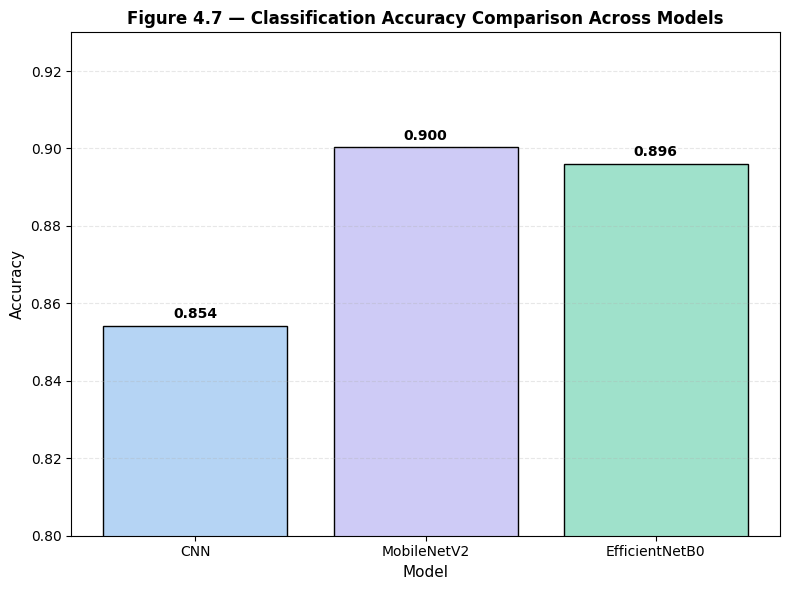

Saved — figure4_7_accuracy_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

models = [
    "CNN",
    "MobileNetV2",
    "EfficientNetB0"
]

accuracy = [
    0.854178,
    0.900275,
    0.896051
]

bars = plt.bar(
    models,
    accuracy,
    color=[
        "#B5D4F4",
        "#CECBF6",
        "#9FE1CB"
    ],
    edgecolor='black'
)

for bar, value in zip(bars, accuracy):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.002,
        f"{value:.3f}",
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

plt.ylim(0.80, 0.93)

plt.ylabel(
    "Accuracy",
    fontsize=11
)

plt.xlabel(
    "Model",
    fontsize=11
)

plt.title(
    "Figure 4.7 — Classification Accuracy Comparison Across Models",
    fontsize=12,
    fontweight='bold'
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "figure4_7_accuracy_comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Saved — figure4_7_accuracy_comparison.png")

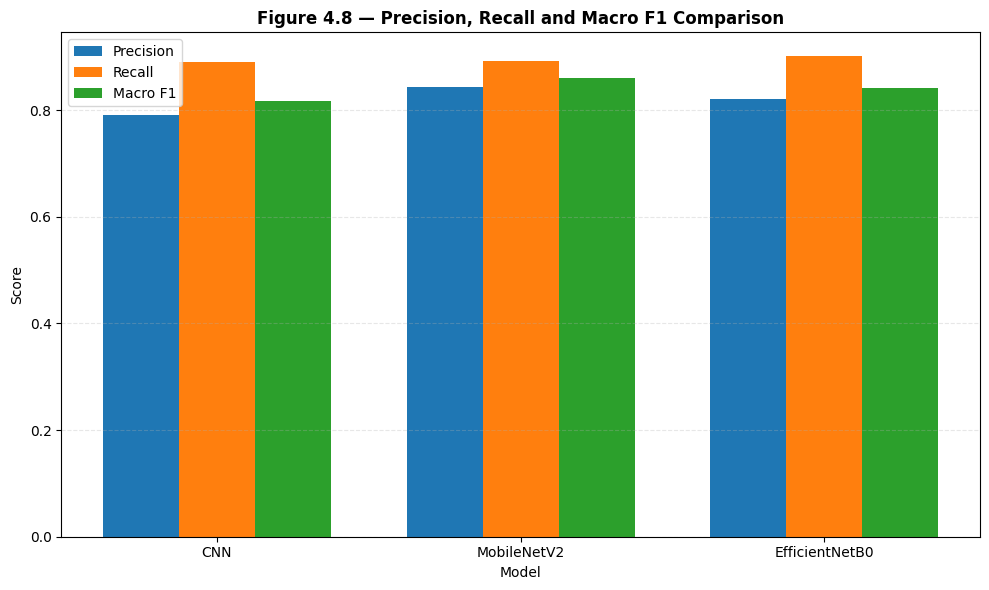

Saved — figure4_8_precision_recall_f1.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

models = [
    "CNN",
    "MobileNetV2",
    "EfficientNetB0"
]

precision = [
    0.791138,
    0.843662,
    0.821435
]

recall = [
    0.890242,
    0.892888,
    0.901154
]

f1 = [
    0.816778,
    0.860262,
    0.842078
]

x = np.arange(len(models))

width = 0.25

plt.figure(figsize=(10,6))

plt.bar(
    x - width,
    precision,
    width,
    label='Precision'
)

plt.bar(
    x,
    recall,
    width,
    label='Recall'
)

plt.bar(
    x + width,
    f1,
    width,
    label='Macro F1'
)

plt.xticks(
    x,
    models
)

plt.ylabel(
    "Score"
)

plt.xlabel(
    "Model"
)

plt.title(
    "Figure 4.8 — Precision, Recall and Macro F1 Comparison",
    fontsize=12,
    fontweight='bold'
)

plt.legend()

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "figure4_8_precision_recall_f1.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Saved — figure4_8_precision_recall_f1.png")

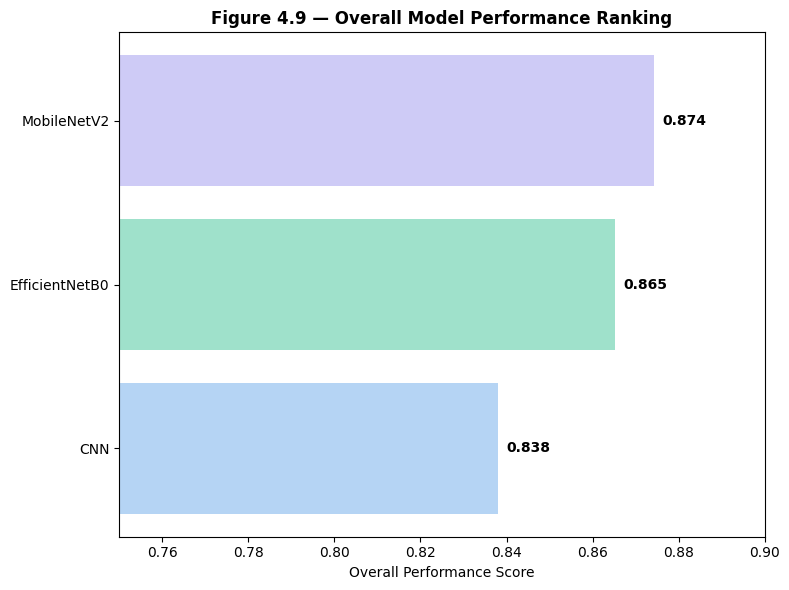

Saved — figure4_9_model_ranking.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

comparison_df["Overall Score"] = (

    comparison_df["Accuracy"]

    + comparison_df["Precision"]

    + comparison_df["Recall"]

    + comparison_df["Macro_F1"]

) / 4

comparison_df = comparison_df.sort_values(
    "Overall Score",
    ascending=True
)

plt.figure(figsize=(8,6))

bars = plt.barh(

    comparison_df["Model"],

    comparison_df["Overall Score"],

    color=[
        "#B5D4F4",
        "#9FE1CB",
        "#CECBF6"
    ]
)

for bar, score in zip(
    bars,
    comparison_df["Overall Score"]
):

    plt.text(

        score + 0.002,

        bar.get_y() + bar.get_height()/2,

        f"{score:.3f}",

        va='center',

        fontsize=10,

        fontweight='bold'
    )

plt.xlim(
    0.75,
    0.90
)

plt.xlabel(
    "Overall Performance Score"
)

plt.title(
    "Figure 4.9 — Overall Model Performance Ranking",
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    "figure4_9_model_ranking.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Saved — figure4_9_model_ranking.png")

In [ ]:
table4_1 = pd.DataFrame({

    "Dataset":[

        "Training",

        "Validation",

        "Test"
    ],

    "Number of Images":[

        24721,

        6180,

        5445
    ],

    "Percentage (%)":[

        round((24721/36346)*100,2),

        round((6180/36346)*100,2),

        round((5445/36346)*100,2)
    ]
})

table4_1

,Dataset,Number of Images,Percentage (%)
0,Training,24721,68.02
1,Validation,6180,17.00
2,Test,5445,14.98


In [ ]:
table4_1.to_csv(
    "table4_1_dataset_split.csv",
    index=False
)

In [ ]:
table4_2 = pd.DataFrame({

    "Metric":[

        "Accuracy",

        "Precision",

        "Recall",

        "Macro F1"
    ],

    "Value":[

        cnn_test_accuracy,

        cnn_precision,

        cnn_recall,

        cnn_f1
    ]
})

table4_2

,Metric,Value
0,Accuracy,0.854178
1,Precision,0.791138
2,Recall,0.890242
3,Macro F1,0.816778


In [ ]:
table4_2.to_csv(
    "table4_2_cnn_results.csv",
    index=False
)

In [ ]:
table4_3 = pd.DataFrame({

    "Metric":[

        "Accuracy",

        "Precision",

        "Recall",

        "Macro F1"
    ],

    "Value":[

        mobile_test_accuracy,

        mobile_precision,

        mobile_recall,

        mobile_f1
    ]
})

table4_3

,Metric,Value
0,Accuracy,0.900275
1,Precision,0.843662
2,Recall,0.892888
3,Macro F1,0.860262


In [ ]:
table4_3.to_csv(
    "table4_3_mobilenet_results.csv",
    index=False
)

In [ ]:
table4_4 = pd.DataFrame({

    "Metric":[

        "Accuracy",

        "Precision",

        "Recall",

        "Macro F1"
    ],

    "Value":[

        efficient_test_accuracy,

        efficient_precision,

        efficient_recall,

        efficient_f1
    ]
})

table4_4

,Metric,Value
0,Accuracy,0.896051
1,Precision,0.821435
2,Recall,0.901154
3,Macro F1,0.842078


In [ ]:
table4_4.to_csv(
    "table4_4_efficientnet_results.csv",
    index=False
)

In [ ]:
table4_5 = pd.DataFrame({

    "Model":[

        "CNN",

        "MobileNetV2",

        "EfficientNetB0"
    ],

    "Accuracy":[

        cnn_test_accuracy,

        mobile_test_accuracy,

        efficient_test_accuracy
    ],

    "Precision":[

        cnn_precision,

        mobile_precision,

        efficient_precision
    ],

    "Recall":[

        cnn_recall,

        mobile_recall,

        efficient_recall
    ],

    "Macro F1":[

        cnn_f1,

        mobile_f1,

        efficient_f1
    ]
})

table4_5

,Model,Accuracy,Precision,Recall,Macro F1
0,CNN,0.854178,0.791138,0.890242,0.816778
1,MobileNetV2,0.900275,0.843662,0.892888,0.860262
2,EfficientNetB0,0.896051,0.821435,0.901154,0.842078


In [ ]:
table4_5.to_csv(
    "table4_5_model_comparison.csv",
    index=False
)

In [ ]:
best_model = table4_5.loc[
    table4_5["Accuracy"].idxmax()
]

table4_6 = pd.DataFrame({

    "Criterion":[

        "Best Model",

        "Accuracy",

        "Precision",

        "Recall",

        "Macro F1"
    ],

    "Value":[

        best_model["Model"],

        best_model["Accuracy"],

        best_model["Precision"],

        best_model["Recall"],

        best_model["Macro F1"]
    ]
})

table4_6

,Criterion,Value
0,Best Model,MobileNetV2
1,Accuracy,0.900275
2,Precision,0.843662
3,Recall,0.892888
4,Macro F1,0.860262


In [ ]:
table4_7 = pd.DataFrame({

    "Model":[

        "MobileNetV2",

        "EfficientNetB0"
    ],

    "Accuracy Gain (%)":[

        ((mobile_test_accuracy - cnn_test_accuracy)
         / cnn_test_accuracy) * 100,

        ((efficient_test_accuracy - cnn_test_accuracy)
         / cnn_test_accuracy) * 100
    ]
})

table4_7

,Model,Accuracy Gain (%)
0,MobileNetV2,5.396689
1,EfficientNetB0,4.902171


Retrieving information from saved files

In [ ]:
import pickle

with open(
    "/content/drive/MyDrive/Insect_Results/training_histories.pkl",
    "rb"
) as f:

    histories = pickle.load(f)

print(histories.keys())

dict_keys(['cnn_history', 'mobilenet_history', 'mobilenet_fine_history', 'efficient_history', 'efficient_fine_history'])


In [ ]:
history_transfer = histories["mobilenet_history"]

history_finetune = histories["mobilenet_fine_history"]

In [ ]:
acc_s1 = history_transfer['accuracy']
val_acc_s1 = history_transfer['val_accuracy']

loss_s1 = history_transfer['loss']
val_loss_s1 = history_transfer['val_loss']

acc_s2 = history_finetune['accuracy']
val_acc_s2 = history_finetune['val_accuracy']

loss_s2 = history_finetune['loss']
val_loss_s2 = history_finetune['val_loss']

acc = acc_s1 + acc_s2
val_acc = val_acc_s1 + val_acc_s2

loss = loss_s1 + loss_s2
val_loss = val_loss_s1 + val_loss_s2

epochs = list(range(1, len(acc)+1))

stage2_start = len(acc_s1)+1

In [ ]:
import tensorflow as tf

TRAIN_DIR = "/content/drive/MyDrive/Insect_Data/train"

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(224,224),
    batch_size=32,
    shuffle=False
)

class_names = train_ds.class_names

Found 30901 files belonging to 16 classes.


In [ ]:
label_counts = {}

for _, labels in train_ds:

    for label in labels.numpy():

        label_counts[label] = (
            label_counts.get(label, 0) + 1
        )

named_counts = {

    class_names[k]: v

    for k, v in sorted(
        label_counts.items(),
        key=lambda x: x[1]
    )
}

NameError: name 'RESULTS_DIR' is not defined

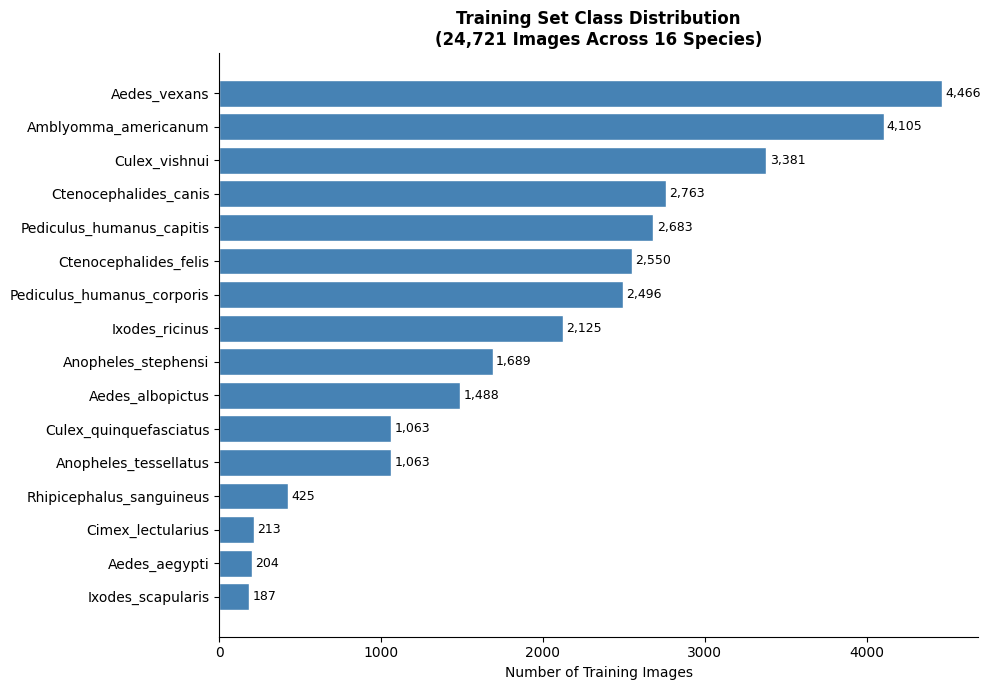

In [ ]:
import os
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    figsize=(10,7)
)

bars = ax.barh(

    list(named_counts.keys()),

    list(named_counts.values()),

    color='steelblue',

    edgecolor='white'
)

for bar, val in zip(
    bars,
    named_counts.values()
):

    ax.text(

        bar.get_width()+20,

        bar.get_y()+bar.get_height()/2,

        f"{val:,}",

        va='center',

        fontsize=9
    )

ax.set_xlabel(
    "Number of Training Images"
)

ax.set_title(

    "Training Set Class Distribution\n(24,721 Images Across 16 Species)",

    fontsize=12,

    fontweight='bold'
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

plt.savefig(

    os.path.join(
        RESULTS_DIR,
        "Class_distribution.png"
    ),

    dpi=300,

    bbox_inches='tight'
)

plt.show()

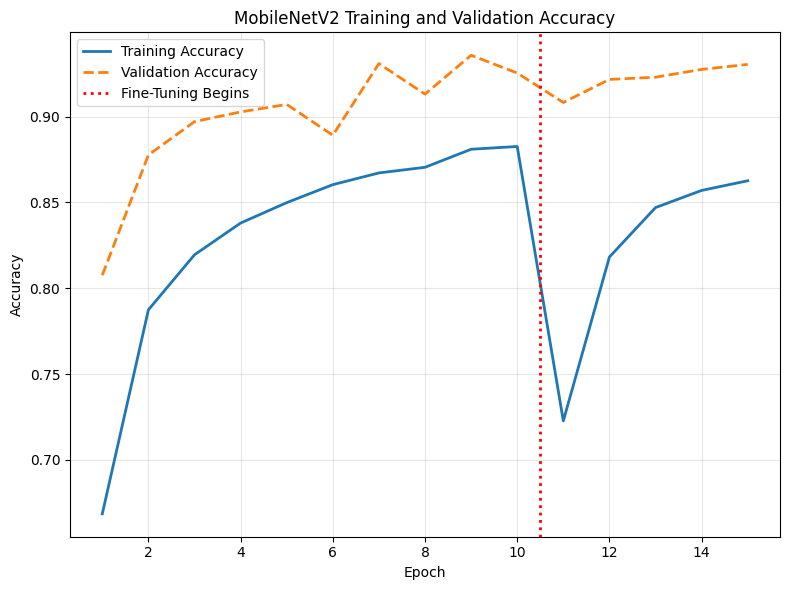

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.plot(
    epochs,
    acc,
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    val_acc,
    linewidth=2,
    linestyle="--",
    label="Validation Accuracy"
)

plt.axvline(
    x=stage2_start-0.5,
    color="red",
    linestyle=":",
    linewidth=2,
    label="Fine-Tuning Begins"
)

plt.title(
    "MobileNetV2 Training and Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "mobilenet_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

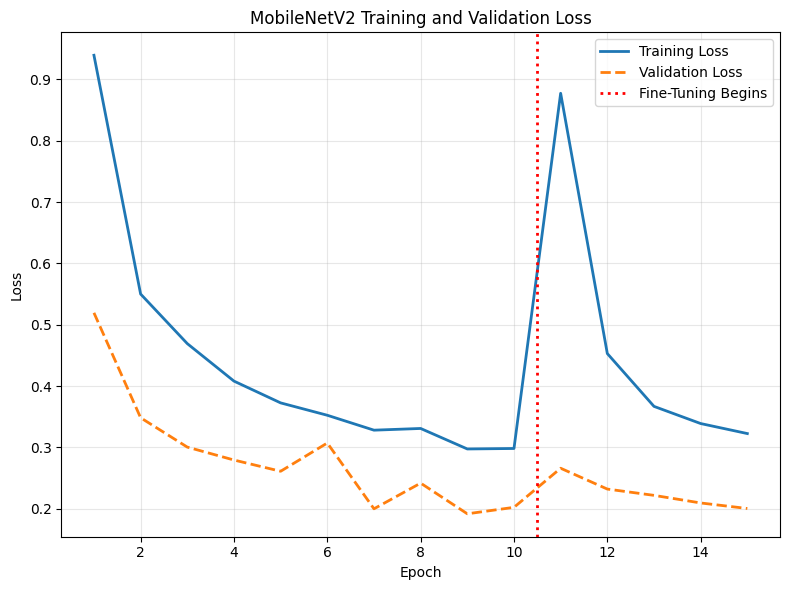

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.plot(
    epochs,
    loss,
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    val_loss,
    linewidth=2,
    linestyle="--",
    label="Validation Loss"
)

plt.axvline(
    x=stage2_start-0.5,
    color="red",
    linestyle=":",
    linewidth=2,
    label="Fine-Tuning Begins"
)

plt.title(
    "MobileNetV2 Training and Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "mobilenet_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

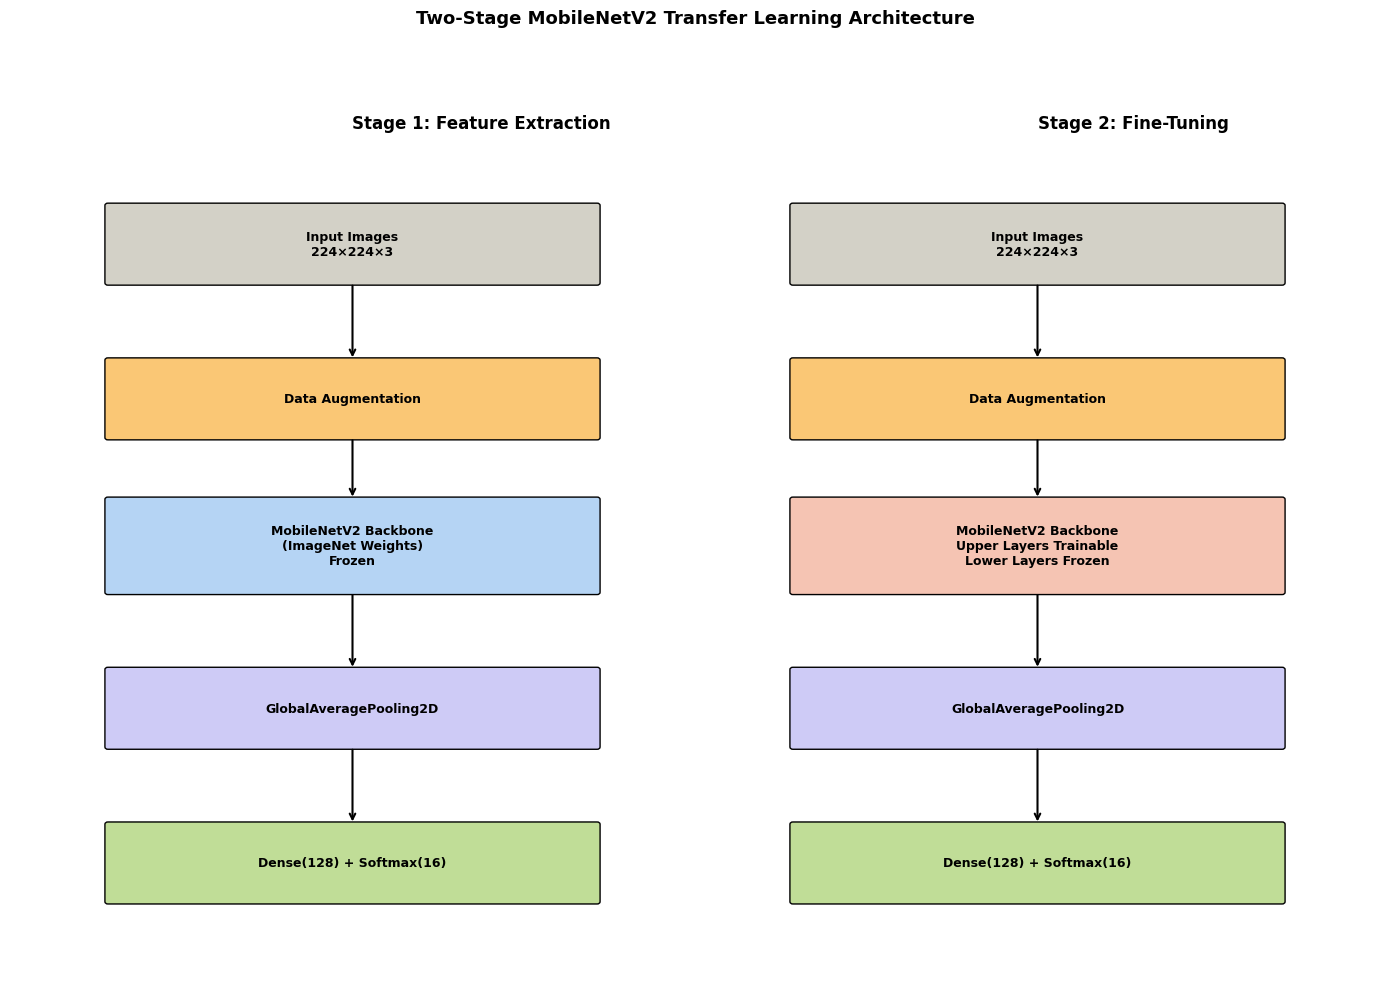

Saved: figure3_3_mobilenetv2_transfer_learning_architecture.png


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 10))
ax.set_xlim(0, 14)
ax.set_ylim(0, 12)
ax.axis('off')

def box(x, y, w, h, text, color):
    rect = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.03",
        facecolor=color,
        edgecolor='black',
        linewidth=1
    )
    ax.add_patch(rect)

    ax.text(
        x+w/2,
        y+h/2,
        text,
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold'
    )

def arrow(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            lw=1.5
        )
    )

# =====================================================
# STAGE 1
# =====================================================

ax.text(
    3.5,
    11,
    "Stage 1: Feature Extraction",
    fontsize=12,
    fontweight='bold'
)

box(1,9,5,1,
    "Input Images\n224×224×3",
    "#D3D1C7")

box(1,7,5,1,
    "Data Augmentation",
    "#FAC775")

box(1,5,5,1.2,
    "MobileNetV2 Backbone\n(ImageNet Weights)\nFrozen",
    "#B5D4F4")

box(1,3,5,1,
    "GlobalAveragePooling2D",
    "#CECBF6")

box(1,1,5,1,
    "Dense(128) + Softmax(16)",
    "#C0DD97")

arrow(3.5,9,3.5,8)
arrow(3.5,7,3.5,6.2)
arrow(3.5,5,3.5,4)
arrow(3.5,3,3.5,2)

# =====================================================
# STAGE 2
# =====================================================

ax.text(
    10.5,
    11,
    "Stage 2: Fine-Tuning",
    fontsize=12,
    fontweight='bold'
)

box(8,9,5,1,
    "Input Images\n224×224×3",
    "#D3D1C7")

box(8,7,5,1,
    "Data Augmentation",
    "#FAC775")

box(8,5,5,1.2,
    "MobileNetV2 Backbone\nUpper Layers Trainable\nLower Layers Frozen",
    "#F5C4B3")

box(8,3,5,1,
    "GlobalAveragePooling2D",
    "#CECBF6")

box(8,1,5,1,
    "Dense(128) + Softmax(16)",
    "#C0DD97")

arrow(10.5,9,10.5,8)
arrow(10.5,7,10.5,6.2)
arrow(10.5,5,10.5,4)
arrow(10.5,3,10.5,2)

plt.title(
    "Two-Stage MobileNetV2 Transfer Learning Architecture",
    fontsize=13,
    fontweight='bold',
    pad=20
)

plt.tight_layout()

plt.savefig(
    "figure3_3_mobilenetv2_transfer_learning_architecture.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved: figure3_3_mobilenetv2_transfer_learning_architecture.png"
)

In [ ]:
import pickle
import json
import pandas as pd
import numpy as np

# load all training histories
with open("/content/drive/MyDrive/Insect_Results/training_histories.pkl", "rb") as f:
    histories = pickle.load(f)

cnn_history              = histories['cnn_history']
mobilenet_history        = histories['mobilenet_history']
mobilenet_fine_history   = histories['mobilenet_fine_history']
efficient_history        = histories['efficient_history']
efficient_fine_history   = histories['efficient_fine_history']

print("CNN history keys       :", list(cnn_history.keys()))
print("CNN epochs trained     :", len(cnn_history['accuracy']))
print()
print("MobileNetV2 Stage 1 epochs :", len(mobilenet_history['accuracy']))
print("MobileNetV2 Stage 2 epochs :", len(mobilenet_fine_history['accuracy']))
print()
print("EfficientNetB0 Stage 1 epochs:", len(efficient_history['accuracy']))
print("EfficientNetB0 Stage 2 epochs:", len(efficient_fine_history['accuracy']))

CNN history keys       : ['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']
CNN epochs trained     : 20

MobileNetV2 Stage 1 epochs : 10
MobileNetV2 Stage 2 epochs : 5

EfficientNetB0 Stage 1 epochs: 10
EfficientNetB0 Stage 2 epochs: 5


In [ ]:
# load final model metrics
with open("/content/drive/MyDrive/Insect_Results/save/final_model_metrics.csv", "r") as f:
    df_metrics = pd.read_csv(f)

print("FINAL MODEL METRICS")
print("=" * 60)
print(df_metrics.to_string(index=False))

FINAL MODEL METRICS
         Model  Accuracy  Precision   Recall  Macro_F1
           CNN  0.854178   0.791138 0.890242  0.816778
   MobileNetV2  0.900275   0.843662 0.892888  0.860262
EfficientNetB0  0.896051   0.821435 0.901154  0.842078


In [ ]:
df_comparison = pd.read_csv(
    "/content/drive/MyDrive/Insect_Results/model_comparison.csv")
print("MODEL COMPARISON")
print("=" * 60)
print(df_comparison.to_string(index=False))

MODEL COMPARISON
         Model  Accuracy  Precision   Recall  Macro_F1
           CNN  0.854178   0.791138 0.890242  0.816778
   MobileNetV2  0.900275   0.843662 0.892888  0.860262
EfficientNetB0  0.896051   0.821435 0.901154  0.842078


In [ ]:
with open("/content/drive/MyDrive/Insect_Results/thesis_artifacts.pkl", "rb") as f:
    artifacts = pickle.load(f)

print("Keys in thesis_artifacts.pkl:")
for key in artifacts.keys():
    val = artifacts[key]
    if hasattr(val, 'shape'):
        print(f"  {key}: array shape {val.shape}")
    elif isinstance(val, list):
        print(f"  {key}: list of {len(val)} items")
    elif isinstance(val, dict):
        print(f"  {key}: dict with keys {list(val.keys())}")
    else:
        print(f"  {key}: {type(val).__name__} = {val}")

Keys in thesis_artifacts.pkl:
  comparison_df: array shape (3, 5)
  cnn_report_df: array shape (19, 4)
  scaling_df: array shape (9, 3)
  class_names: list of 16 items
  cnn_metrics: dict with keys ['accuracy', 'precision', 'recall', 'f1']
  mobilenet_metrics: dict with keys ['accuracy', 'precision', 'recall', 'f1']
  efficientnet_metrics: dict with keys ['accuracy', 'precision', 'recall', 'f1']


5 out of 5

In [ ]:
import numpy as np
import pickle
import json
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/Insect_Results/save"

# ── load confusion matrices ───────────────────────────────────────
cnn_cm  = np.load(f"{BASE}/cnn_confusion_matrix.npy")
mv2_cm  = np.load(f"{BASE}/mobilenet_confusion_matrix.npy")
eff_cm  = np.load(f"{BASE}/efficientnet_confusion_matrix.npy")

print("CNN confusion matrix shape      :", cnn_cm.shape)
print("MobileNetV2 confusion matrix    :", mv2_cm.shape)
print("EfficientNetB0 confusion matrix :", eff_cm.shape)

# ── load class names ──────────────────────────────────────────────
with open(f"{BASE}/class_names.json", "r") as f:
    class_names = json.load(f)

print("\nClass names:", class_names)
print("Number of classes:", len(class_names))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CNN confusion matrix shape      : (16, 16)
MobileNetV2 confusion matrix    : (16, 16)
EfficientNetB0 confusion matrix : (16, 16)

Class names: ['Aedes_aegypti', 'Aedes_albopictus', 'Aedes_vexans', 'Amblyomma_americanum', 'Anopheles_stephensi', 'Anopheles_tessellatus', 'Cimex_lectularius', 'Ctenocephalides_canis', 'Ctenocephalides_felis', 'Culex_quinquefasciatus', 'Culex_vishnui', 'Ixodes_ricinus', 'Ixodes_scapularis', 'Pediculus_humanus_capitis', 'Pediculus_humanus_corporis', 'Rhipicephalus_sanguineus']
Number of classes: 16


In [ ]:
BASE = "/content/drive/MyDrive/Insect_Results/"

with open(f"{BASE}/thesis_artifacts.pkl", "rb") as f:
    artifacts = pickle.load(f)

# per-class CNN report
cnn_report_df = artifacts['cnn_report_df']
print("CNN Per-Class Report:")
print(cnn_report_df.to_string())
print()

# scaling experiment results
scaling_df = artifacts['scaling_df']
print("RQ3 Scaling Experiment:")
print(scaling_df.to_string(index=False))
print()

# individual model metrics
for name, key in [
    ("CNN",          "cnn_metrics"),
    ("MobileNetV2",  "mobilenet_metrics"),
    ("EfficientNetB0","efficientnet_metrics"),
]:
    m = artifacts[key]
    print(f"{name}: Acc={m['accuracy']:.4f}  "
          f"P={m['precision']:.4f}  "
          f"R={m['recall']:.4f}  "
          f"F1={m['f1']:.4f}")

CNN Per-Class Report:
                            precision    recall  f1-score      support
Aedes_aegypti                0.329897  0.914286  0.484848    35.000000
Aedes_albopictus             0.934066  0.973282  0.953271   262.000000
Aedes_vexans                 0.935737  0.758577  0.837895   787.000000
Amblyomma_americanum         0.933227  0.810773  0.867701   724.000000
Anopheles_stephensi          0.977273  0.865772  0.918149   298.000000
Anopheles_tessellatus        0.593857  0.930481  0.725000   187.000000
Cimex_lectularius            1.000000  1.000000  1.000000    37.000000
Ctenocephalides_canis        0.908537  0.917864  0.913177   487.000000
Ctenocephalides_felis        0.957447  0.900000  0.927835   450.000000
Culex_quinquefasciatus       0.550769  0.957219  0.699219   187.000000
Culex_vishnui                0.811741  0.672819  0.735780   596.000000
Ixodes_ricinus               0.938375  0.893333  0.915301   375.000000
Ixodes_scapularis            0.484375  0.968750  0.6458

In [ ]:
# normalise confusion matrices by row to get per-class recall
def print_per_class_recall(cm, class_names, model_name):
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    recalls = cm_norm.diagonal()
    print(f"\n{model_name} — Per-Class Recall")
    print(f"{'Species':<45} {'Recall':>8}")
    print("-" * 55)
    for cls, rec in sorted(
            zip(class_names, recalls), key=lambda x: -x[1]):
        print(f"  {cls:<43} {rec:>8.4f}")
    print(f"\n  Macro Recall: {recalls.mean():.4f}")

print_per_class_recall(cnn_cm,  class_names, "CNN from Scratch")
print_per_class_recall(mv2_cm,  class_names, "MobileNetV2")
print_per_class_recall(eff_cm,  class_names, "EfficientNetB0")


CNN from Scratch — Per-Class Recall
Species                                         Recall
-------------------------------------------------------
  Cimex_lectularius                             1.0000
  Aedes_albopictus                              0.9733
  Ixodes_scapularis                             0.9688
  Culex_quinquefasciatus                        0.9572
  Pediculus_humanus_corporis                    0.9477
  Anopheles_tessellatus                         0.9305
  Pediculus_humanus_capitis                     0.9197
  Ctenocephalides_canis                         0.9179
  Aedes_aegypti                                 0.9143
  Ctenocephalides_felis                         0.9000
  Ixodes_ricinus                                0.8933
  Anopheles_stephensi                           0.8658
  Rhipicephalus_sanguineus                      0.8133
  Amblyomma_americanum                          0.8108
  Aedes_vexans                                  0.7586
  Culex_vishnui            

In [ ]:
BASE = "/content/drive/MyDrive/Insect_Results/"

with open(f"{BASE}/history_cnn.pkl", "rb") as f:
    cnn_hist = pickle.load(f)

h = cnn_hist.history if hasattr(cnn_hist, 'history') else cnn_hist

print("CNN Training History — epoch by epoch:")
print(f"{'Epoch':<8} {'Train Acc':>10} {'Val Acc':>10} "
      f"{'Train Loss':>12} {'Val Loss':>10}")
print("-" * 55)
for i, (ta, va, tl, vl) in enumerate(zip(
        h['accuracy'], h['val_accuracy'],
        h['loss'],     h['val_loss']), 1):
    print(f"  {i:<6} {ta:>10.4f} {va:>10.4f} "
          f"{tl:>12.4f} {vl:>10.4f}")

CNN Training History — epoch by epoch:
Epoch     Train Acc    Val Acc   Train Loss   Val Loss
-------------------------------------------------------
  1          0.0519     0.0045       3.1845     2.8635
  2          0.0369     0.1240       2.8427     2.7672
  3          0.0289     0.0118       2.8005     2.8419
  4          0.0271     0.0180       2.7884     2.7830
  5          0.0210     0.0069       2.7812     2.8369
  6          0.0143     0.0411       2.7770     2.7869
  7          0.0231     0.0083       2.7792     2.7655
  8          0.0238     0.0080       2.7781     2.7831


In [ ]:
# consolidate all numbers into one readable text file
# so we have a permanent record for thesis writing

summary_lines = []

summary_lines.append("=" * 65)
summary_lines.append("THESIS RESULTS SUMMARY")
summary_lines.append("=" * 65)

summary_lines.append("\nDATASET SPLIT")
summary_lines.append("  Training   : 24,721 images (68%)")
summary_lines.append("  Validation :  6,180 images (17%)")
summary_lines.append("  Test       :  5,445 images (15%)")
summary_lines.append("  Total      : 36,346 images, 16 species")

summary_lines.append("\nMODEL RESULTS (TEST SET)")
summary_lines.append(f"{'Model':<20} {'Accuracy':>10} "
                     f"{'Precision':>10} {'Recall':>10} {'F1':>10}")
summary_lines.append("-" * 65)
BASE = "/content/drive/MyDrive/Insect_Results/save/"
for _, row in pd.read_csv(f"{BASE}/final_model_metrics.csv").iterrows():
    summary_lines.append(
        f"  {row['Model']:<18} {row['Accuracy']:>10.4f} "
        f"{row['Precision']:>10.4f} {row['Recall']:>10.4f} "
        f"{row['Macro_F1']:>10.4f}")

summary_lines.append("\nTRAINING EPOCHS")
summary_lines.append("  CNN                  : 20 epochs")
summary_lines.append("  MobileNetV2 Stage 1  : 10 epochs")
summary_lines.append("  MobileNetV2 Stage 2  :  5 epochs  (fine-tuning)")
summary_lines.append("  EfficientNetB0 S1    : 10 epochs")
summary_lines.append("  EfficientNetB0 S2    :  5 epochs  (fine-tuning)")

summary_text = "\n".join(summary_lines)
print(summary_text)

with open(f"{BASE}/THESIS_SUMMARY.txt", "w") as f:
    f.write(summary_text)
print(f"\nSaved to {BASE}/THESIS_SUMMARY.txt")

THESIS RESULTS SUMMARY

DATASET SPLIT
  Training   : 24,721 images (68%)
  Validation :  6,180 images (17%)
  Test       :  5,445 images (15%)
  Total      : 36,346 images, 16 species

MODEL RESULTS (TEST SET)
Model                  Accuracy  Precision     Recall         F1
-----------------------------------------------------------------
  CNN                    0.8542     0.7911     0.8902     0.8168
  MobileNetV2            0.9003     0.8437     0.8929     0.8603
  EfficientNetB0         0.8961     0.8214     0.9012     0.8421

TRAINING EPOCHS
  CNN                  : 20 epochs
  MobileNetV2 Stage 1  : 10 epochs
  MobileNetV2 Stage 2  :  5 epochs  (fine-tuning)
  EfficientNetB0 S1    : 10 epochs
  EfficientNetB0 S2    :  5 epochs  (fine-tuning)

Saved to /content/drive/MyDrive/Insect_Results/save//THESIS_SUMMARY.txt
